**Contents**

**0. Base tables**
- 0.1 Daily trips, whole city → `data/daily_counts_city.csv`
- 0.2 Hourly trips, whole city → `data/hourly_counts.parquet`

**1. Is 2022–2025 a stable period to define "normal"?**
- 1.1 Daily rhythm: Plot 1 weekdays vs weekends · Plot 2 year by year (2 versions) · Plot 3 distance to 2022–2025 (4 rhythms)
- 1.2 Rider mix: casual share per month · seasonality members vs casual · hours members vs casual
- 1.3 Total volume: trips per year
- 1.4 Network size: active stations per month
- 1.5 E-bikes: by hour · evening trips by bike type · by month · seasonality vs classic bikes · by rider type

**2. Choice of the grid**
- 2.1 Method: how many trips are needed to detect an anomaly?
- 2.2 Zones: the 77 community areas · trips outside the zones · 700 m rule → `data/zone_hourly_counts.parquet`
- 2.3 Day vs hour: trips per cell · noise of the counts (CV)
- 2.4 Which zones have enough trips per day?
- 2.5 Hybrid grid: first version · second version (final) → `data/zone_to_cell.csv`
- 2.6 Checks of the grid: winter · splitting groups in summer
- 2.7 Final table: trips per cell per day → `data/daily_counts_cells.parquet`

**3. Stations**
- Share of trips starting at a station · map of stations · docking stations vs public racks

## 0. Base tables
- function need to be stored in `src/data/counts.py`

### 0.1 Daily trips, whole city → `data/daily_counts_city.csv`

➕ One row per day: trips, members, casual riders, e-bikes. 
- file useful for the weather analysis can also use the file 2

In [9]:
import pandas as pd
from src.data.counts import daily_counts_city

daily_city = daily_counts_city()
daily_city.to_csv("data/daily_counts_city.csv")
print(len(daily_city), "days")
daily_city.tail()

4840 days


,n_trips,n_member,n_casual,n_electric
date,,,,
2026-09-26,28055,15160,12895,20368
2026-09-27,23996,13211,10785,17320
2026-09-28,25561,17088,8473,18590
2026-09-29,26564,19039,7525,19420
2026-09-30,9721,7227,2494,7546


### 0.2 Hourly trips, whole city → `data/hourly_counts.parquet`

➕ One row per hour : number trips, by rider type and bike type
- Result: 329,949 rows, 57,339,375 trips (matches the clean data), saved in 
-  All the time plots of section 1 use this table.

In [10]:
import glob
import pandas as pd

def hourly_counts(clean_dir="data/clean"):
    """Number of trips per hour, by user type and bike type (read file by file)."""
    parts = []
    for f in sorted(glob.glob(f"{clean_dir}/*__*.parquet")):
        df = pd.read_parquet(f, columns=["started_at", "user_type", "bike_type"])
        df["user_type"] = df["user_type"].fillna("member")  # 190 "Dependent" trips (2015-2017)
        df["hour"] = df["started_at"].dt.floor("h")
        parts.append(df.groupby(["hour", "user_type", "bike_type"]).size())
    counts = pd.concat(parts).groupby(level=[0, 1, 2]).sum()
    return counts.rename("n_trips").reset_index()

hourly = hourly_counts()
hourly.to_parquet("data/hourly_counts.parquet")
print(len(hourly), "rows,", hourly["n_trips"].sum(), "trips")
hourly.head()

329949 rows, 57339375 trips


,hour,user_type,bike_type,n_trips
0,2013-06-27 01:00:00,member,classic,1
1,2013-06-27 11:00:00,member,classic,4
2,2013-06-27 12:00:00,casual,classic,1
3,2013-06-27 12:00:00,member,classic,2
4,2013-06-27 13:00:00,member,classic,2


## 1. Is 2022–2025 a stable period to define "normal"?

➕ Summary: demand stable (±3% per year), rider mix stable, network roughly flat in 2022–2024 (growing again in 2025), weekly and seasonal rhythms stable over 2022–2025. 2022 is only apart in the hourly profiles, which do not matter for daily counts 

- keep 2022–2025: the small differences between years could be handled in the model by giving each year its own base level (a "year effect") : TO ADD

### 1.1 Daily rhythm: share of trips by hour of the day

### Plot 1: Share of trips by hour, weekdays vs weekends, before vs after COVID

- For the model: weekday vs weekend must be in the “normal” model, since the two rhythms are completely different.
- For the period: the rhythm before and after COVID is not the same, so mixing 2014–2019 with 2022–2025 would mix two different “normals”. This is another argument for 2022–2025.

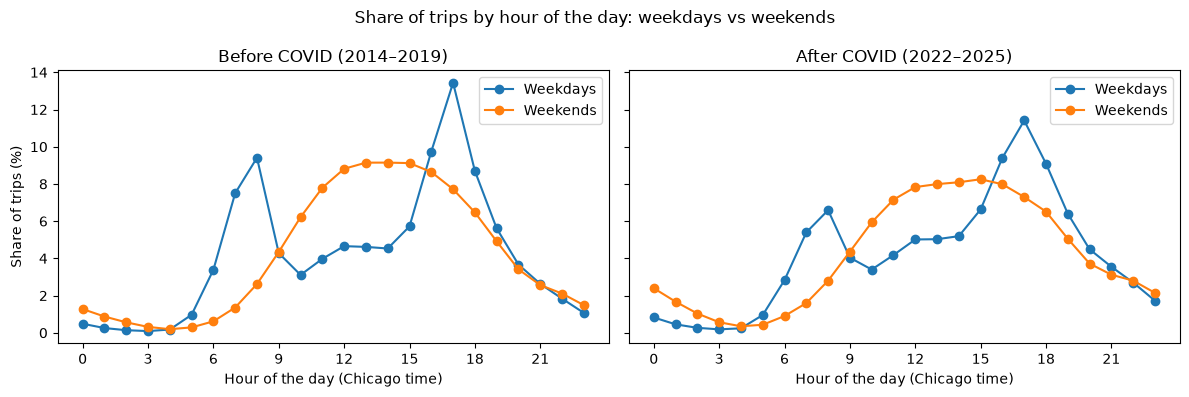

In [11]:
import matplotlib.pyplot as plt

h = hourly.copy()
h["hour_of_day"] = h["hour"].dt.hour
h["weekend"] = h["hour"].dt.dayofweek >= 5          # Saturday = 5, Sunday = 6
h["year"] = h["hour"].dt.year

periods = {"Before COVID (2014–2019)": (2014, 2019),
           "After COVID (2022–2025)": (2022, 2025)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, (start, end)) in zip(axes, periods.items()):
    sub = h[h["year"].between(start, end)]
    for is_weekend, label in [(False, "Weekdays"), (True, "Weekends")]:
        counts = sub[sub["weekend"] == is_weekend].groupby("hour_of_day")["n_trips"].sum()
        ax.plot(counts.index, 100 * counts / counts.sum(), marker="o", label=label)
    ax.set_title(title)
    ax.set_xlabel("Hour of the day (Chicago time)")
    ax.set_xticks(range(0, 24, 3))
    ax.legend()
axes[0].set_ylabel("Share of trips (%)")
fig.suptitle("Share of trips by hour of the day: weekdays vs weekends")
plt.tight_layout()
plt.show()

### Plot 2: hour-of-day profile, year by year

- 2022–2025 is more stable : the daily rhythm of weekdays changed a lot before 2022, and stays almost fixed after.
- Day vs hour for the grid: between 1:00 and 5:00, each hour holds less than 1% of trips. In a zone × hour grid, these night cells would be almost always empty. That’s a first argument for daily counts

➕ First version (2022–2025 in colour, older years in grey). Redone with a colour gradient in the next cell.

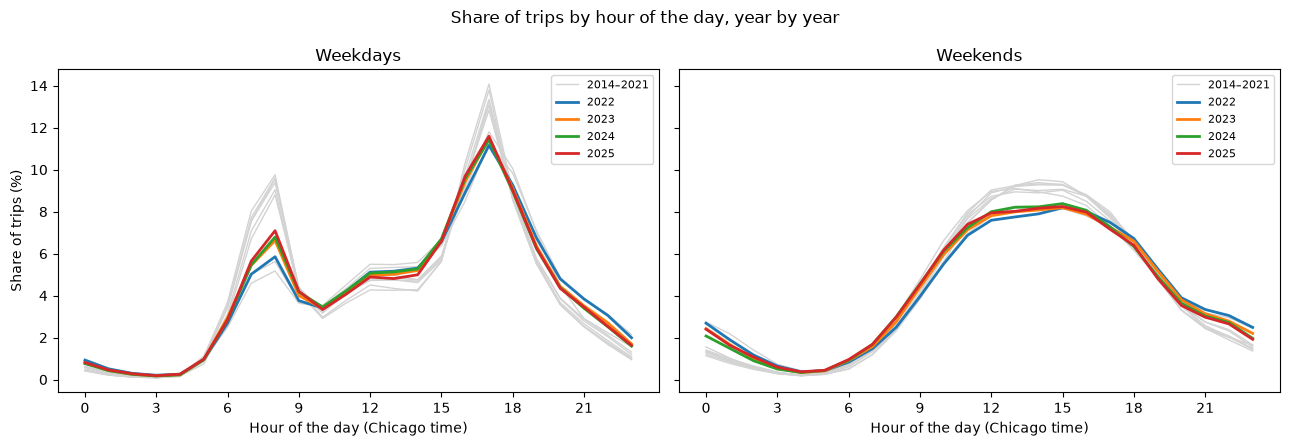

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

hourly = pd.read_parquet("data/hourly_counts.parquet")
h = hourly.copy()
h["hour_of_day"] = h["hour"].dt.hour
h["weekend"] = h["hour"].dt.dayofweek >= 5
h["year"] = h["hour"].dt.year

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (is_weekend, title) in zip(axes, [(False, "Weekdays"), (True, "Weekends")]):
    sub = h[h["weekend"] == is_weekend]
    for year in range(2014, 2026):
        counts = sub[sub["year"] == year].groupby("hour_of_day")["n_trips"].sum()
        if year >= 2022:
            ax.plot(counts.index, 100 * counts / counts.sum(), lw=2, label=str(year))
        else:
            ax.plot(counts.index, 100 * counts / counts.sum(), color="lightgrey", lw=1,
                    label="2014–2021" if year == 2014 else None)
    ax.set_title(title)
    ax.set_xlabel("Hour of the day (Chicago time)")
    ax.set_xticks(range(0, 24, 3))
    ax.legend(fontsize=8)
axes[0].set_ylabel("Share of trips (%)")
fig.suptitle("Share of trips by hour of the day, year by year")
plt.tight_layout()
plt.show()

#### Plot 2, second version: colour gradient by year (one figure for weekdays, one for weekends)

➕ Result: morning peak at 8:00 about 9–9.7% of weekday trips in 2014–2019, the lowest in 2020–2021 (about 5.2–5.6%), about 5.8% in 2022, then 6.7–7.1% in 2023–2025: 2021 is close to 2020, not to 2022–2025. Weekend rhythm: one wide afternoon peak every year.

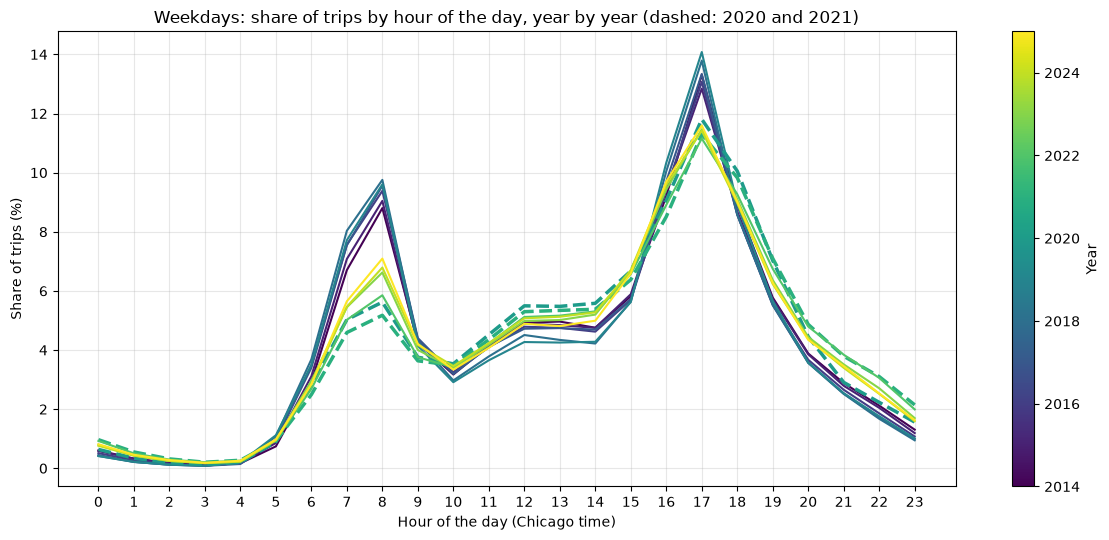

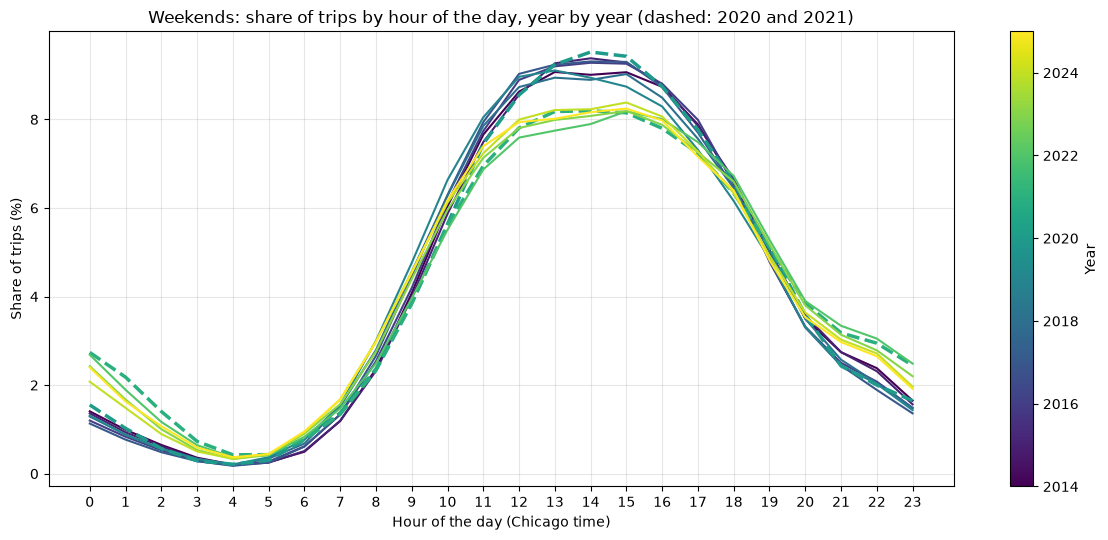

In [13]:
import matplotlib as mpl

years = range(2014, 2026)
cmap = mpl.colormaps["viridis"]
norm = mpl.colors.Normalize(vmin=min(years), vmax=max(years))

for is_weekend, title in [(False, "Weekdays"), (True, "Weekends")]:
    sub = h[h["weekend"] == is_weekend]

    fig, ax = plt.subplots(figsize=(12, 5.5))
    for year in years:
        counts = sub[sub["year"] == year].groupby("hour_of_day")["n_trips"].sum()
        ax.plot(counts.index, 100 * counts / counts.sum(), color=cmap(norm(year)),
                lw=2.5 if year in (2020, 2021) else 1.5,
                ls="--" if year in (2020, 2021) else "-")

    ax.set_title(f"{title}: share of trips by hour of the day, year by year "
                 "(dashed: 2020 and 2021)")
    ax.set_xlabel("Hour of the day (Chicago time)")
    ax.set_ylabel("Share of trips (%)")
    ax.set_xticks(range(0, 24))
    ax.grid(alpha=0.3)
    fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="Year")
    plt.tight_layout()
    plt.show()

- dash point are the limit years : 2020 and 2021 

#### Plot 3: how different is each year from 2022–2025? (4 rhythms)

➕ Method: for each year, share of trips in each category (24 hours, 7 days, 12 months), compared with the 2022–2025 average; the gaps are summed (in % points). Small = same rhythm as 2022–2025.
- **Weekdays by hour:** 11.5–20.1 before COVID, 7.6–8.5 in 2020–2021, 4.7 in 2022, 0.7–2.9 in 2023–2025.
- **Weekends by hour:** already stable in 2021 (4.9).
- **Day of the week:** 2022–2025 almost identical (1.8–2.2).
- **Month:** 2022–2025 at ~5–6 (normal weather noise from year to year).
- Conclusion: 2022 is only apart in the hourly profiles, which do not matter for daily counts → keep 2022–2025 (with a year effect).

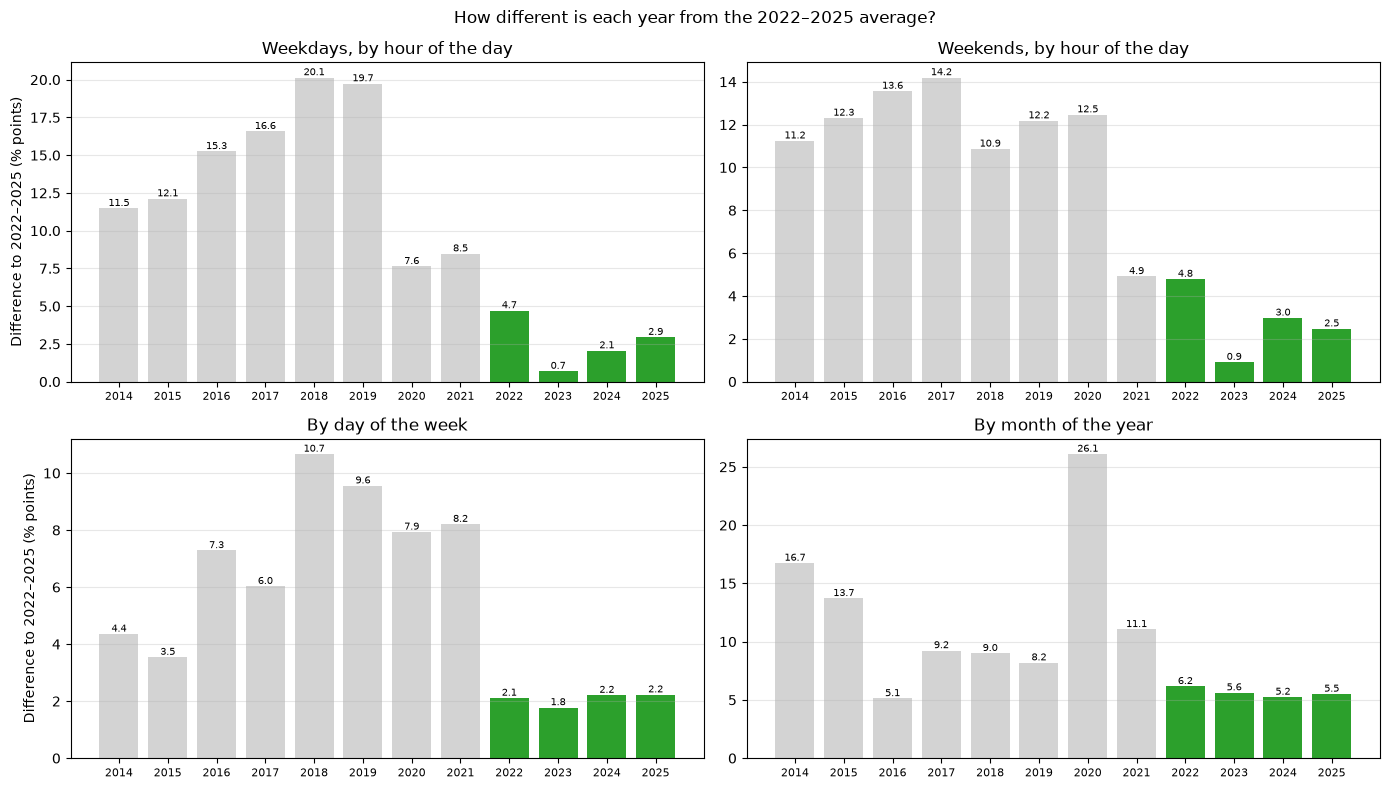

In [14]:
def distance_to_reference(profiles, ref_years=(2022, 2025)):
    """Sum over categories of |share(year) - mean share over the reference years|, in % points."""
    shares = 100 * profiles.div(profiles.sum(axis=1), axis=0)
    reference = shares.loc[ref_years[0]:ref_years[1]].mean()
    return (shares - reference).abs().sum(axis=1)

full = h[h["year"].between(2014, 2025)].copy()
full["dayofweek"] = full["hour"].dt.dayofweek
full["month"] = full["hour"].dt.month

profiles = {
    "Weekdays, by hour of the day":
        full[~full["weekend"]].groupby(["year", "hour_of_day"])["n_trips"].sum().unstack(),
    "Weekends, by hour of the day":
        full[full["weekend"]].groupby(["year", "hour_of_day"])["n_trips"].sum().unstack(),
    "By day of the week":
        full.groupby(["year", "dayofweek"])["n_trips"].sum().unstack(),
    "By month of the year":
        full.groupby(["year", "month"])["n_trips"].sum().unstack(),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (title, prof) in zip(axes.flat, profiles.items()):
    dist = distance_to_reference(prof)
    colors = ["tab:green" if 2022 <= y <= 2025 else "lightgrey" for y in dist.index]
    bars = ax.bar(dist.index, dist.values, color=colors)
    for bar, value in zip(bars, dist.values):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.1f}",
                ha="center", va="bottom", fontsize=7)
    ax.set_title(title)
    ax.set_xticks(dist.index)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3, axis="y")
axes[0, 0].set_ylabel("Difference to 2022–2025 (% points)")
axes[1, 0].set_ylabel("Difference to 2022–2025 (% points)")
fig.suptitle("How different is each year from the 2022–2025 average?")
plt.tight_layout()
plt.show()

### 1.2 Rider mix: members vs casual riders

### Plot 4 : share of casual riders and of e-bikes per month

- Casual riders support 2022–2025 : the mix of riders is stable over the period. From 2022 to 2025 the casual share is very stable (about 42–48% in summer, 17–21% in winter), much higher in winter than before 2020 (about 18% vs 4%). 
- E-bikes : plateau around 45–58% in 2022–2024, rising again from 2025 (about 62–67%).
- The e-bike curve on this plot is analysed in 1.5.

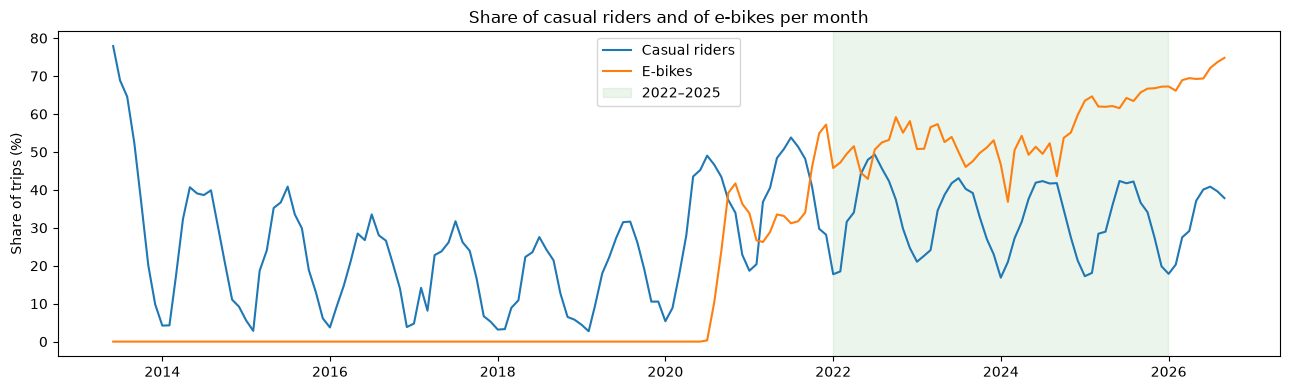

In [15]:
monthly_user = h.groupby([h["hour"].dt.to_period("M"), "user_type"])["n_trips"].sum().unstack()
casual_share = 100 * monthly_user["casual"] / monthly_user.sum(axis=1)

monthly_bike = h.groupby([h["hour"].dt.to_period("M"), "bike_type"])["n_trips"].sum().unstack(fill_value=0)
electric_share = 100 * monthly_bike["electric"] / monthly_bike.sum(axis=1)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(casual_share.index.to_timestamp(), casual_share, label="Casual riders")
ax.plot(electric_share.index.to_timestamp(), electric_share, label="E-bikes")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2025-12-31"),
           color="green", alpha=0.08, label="2022–2025")
ax.set_ylabel("Share of trips (%)")
ax.set_title("Share of casual riders and of e-bikes per month")
ax.legend()
plt.tight_layout()
plt.show()

#### Seasonality: members vs casual riders (share of each rider type's yearly trips, by month, 2022–2025)

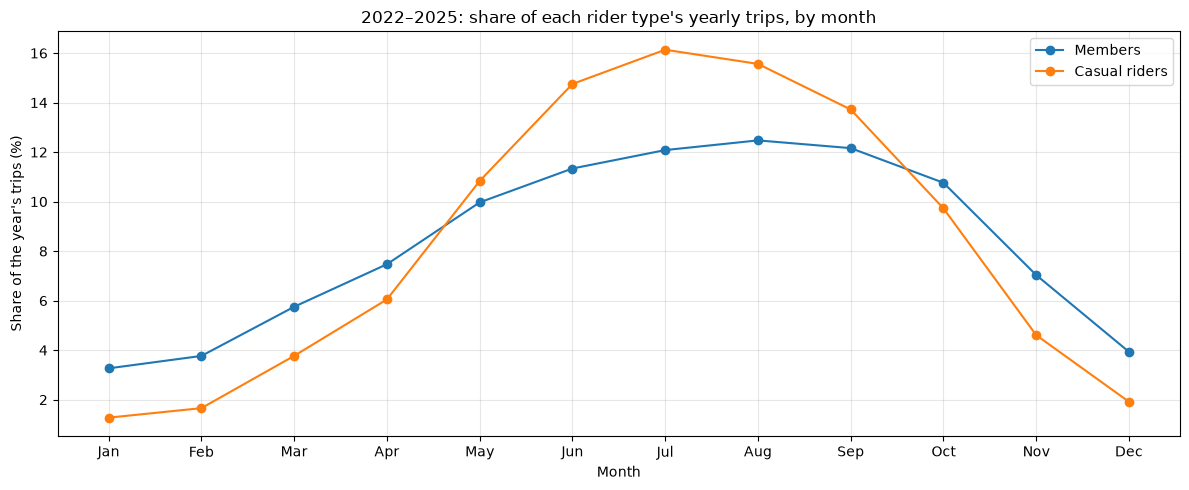

In [16]:
recent = h[h["year"].between(2022, 2025)]
by_type = recent.groupby(["year", recent["hour"].dt.month, "user_type"])["n_trips"].sum()
profile = (by_type / by_type.groupby(level=["year", "user_type"]).transform("sum") * 100)
profile = profile.groupby(level=[1, 2]).mean().unstack()

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(12, 5))
for user, label in [("member", "Members"), ("casual", "Casual riders")]:
    ax.plot(profile.index, profile[user], marker="o", label=label)
ax.set_title("2022–2025: share of each rider type's yearly trips, by month")
ax.set_xlabel("Month")
ax.set_ylabel("Share of the year's trips (%)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

riders type more sensitive to the season than bikes type 

#### Weekdays 2022–2025: share of trips by hour, members vs casual riders

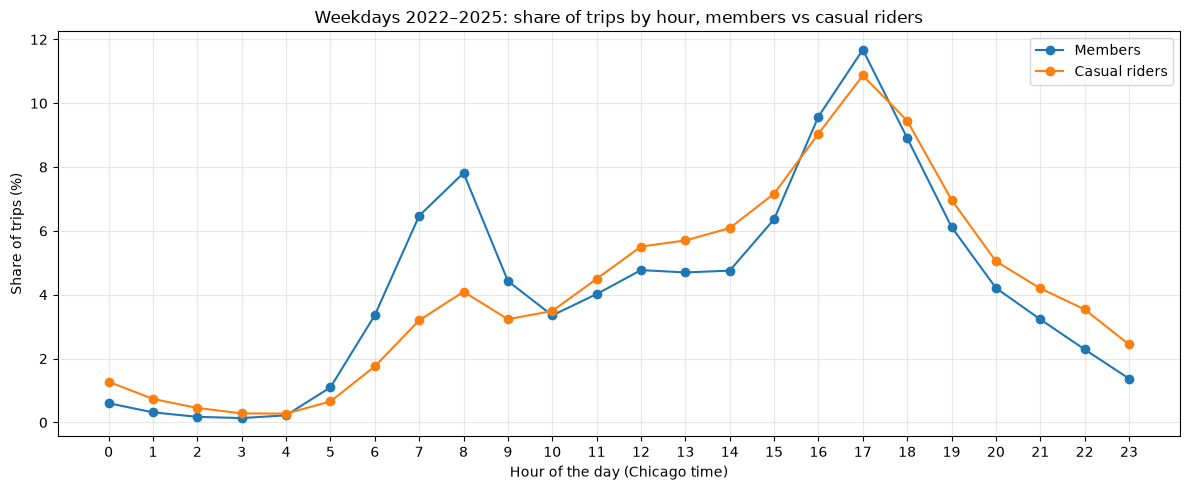

In [17]:
recent = h[h["year"].between(2022, 2025) & ~h["weekend"]]

fig, ax = plt.subplots(figsize=(12, 5))
for user, label in [("member", "Members"), ("casual", "Casual riders")]:
    counts = recent[recent["user_type"] == user].groupby("hour_of_day")["n_trips"].sum()
    ax.plot(counts.index, 100 * counts / counts.sum(), marker="o", label=label)
ax.set_title("Weekdays 2022–2025: share of trips by hour, members vs casual riders")
ax.set_xlabel("Hour of the day (Chicago time)")
ax.set_ylabel("Share of trips (%)")
ax.set_xticks(range(0, 24))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

- The big difference is the morning: the 8:00 peak is mostly members going to work. Casual riders spread their trips more over midday and the evening.
- For the model: the two groups have different rhythms, but less different than weekdays vs weekends. Modelling them separately is questionnable ???

### 1.3 Total volume

### total number of trips change

➕ Result (next cell): 5.54 M trips (2022), 5.56 M (2023), 5.72 M (2024), 5.40 M (2025): within about ±3% over 2022–2025; mean summer month about 720,000–775,000. Same numbers as a bar chart in the cell after (2022–2025 in green, 2013 and 2026 hatched as incomplete).

In [18]:
monthly_total = h.groupby(h["hour"].dt.to_period("M"))["n_trips"].sum()
yearly = monthly_total.groupby(monthly_total.index.year).sum()
summer = monthly_total[monthly_total.index.month.isin([6, 7, 8])]
print("Total trips per year:\n", yearly.loc[2021:2025])
print("\nMean summer month:\n", summer.groupby(summer.index.year).mean().loc[2021:2025].round())

Total trips per year:
 hour
2021    5505068
2022    5539204
2023    5563754
2024    5721284
2025    5399753
Name: n_trips, dtype: int64

Mean summer month:
 hour
2021    772748.0
2022    774707.0
2023    732870.0
2024    720393.0
2025    721214.0
Name: n_trips, dtype: float64


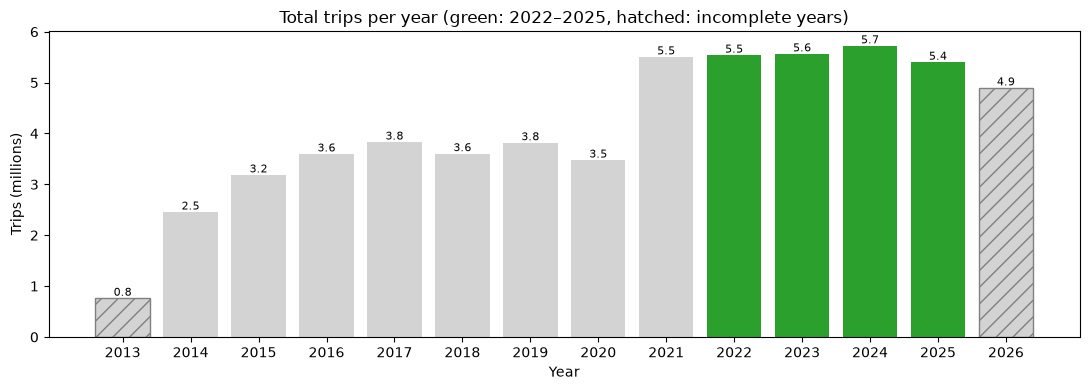

In [19]:
yearly = h.groupby(h["hour"].dt.year)["n_trips"].sum() / 1e6   # in millions

colors = ["tab:green" if 2022 <= y <= 2025 else "lightgrey" for y in yearly.index]

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(yearly.index, yearly.values, color=colors)

# 2013 and 2026 are incomplete years: hatch them and say so
for bar, year in zip(bars, yearly.index):
    if year in (2013, 2026):
        bar.set_hatch("//")
        bar.set_edgecolor("grey")

# value on top of each bar
for bar, value in zip(bars, yearly.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.05, f"{value:.1f}",
            ha="center", fontsize=8)

ax.set_xticks(yearly.index)
ax.set_xlabel("Year")
ax.set_ylabel("Trips (millions)")
ax.set_title("Total trips per year (green: 2022–2025, hatched: incomplete years)")
plt.tight_layout()
plt.show()

### 1.4 Network size

### Network growth : active station per month 
- a station counts as active in a month if at least 10 trips start
- The threshold removes stations that appear only a few times (temporary, moved, or typos)
- One limit to mention: it only counts stations. E-bike trips that start outside a station (after 2020) are not included

➕ Result: about 300 stations (2013–2014) → 630 (2020) → 710 (2021); roughly flat in 2022–2024 (summer about 840–890); growing again in 2025 (about 960) and 2026 (about 1,150). The winter dips are seasonal (outer stations with fewer than 10 trips), not stations closing.

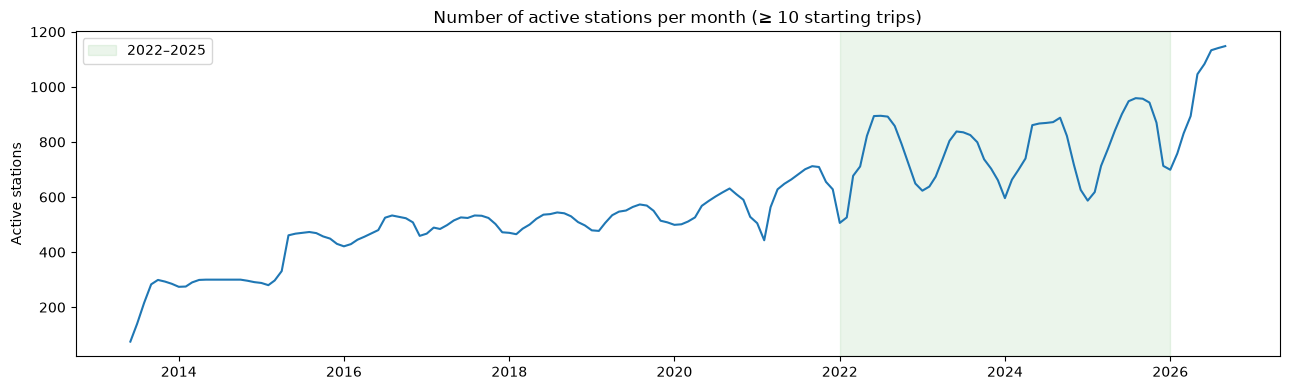

In [20]:
def active_stations_per_month(clean_dir="data/clean", min_trips=10):
    """Number of stations with at least `min_trips` starting trips, per month."""
    parts = []
    for f in sorted(glob.glob(f"{clean_dir}/*__*.parquet")):
        df = pd.read_parquet(f, columns=["started_at", "start_station_name"])
        df = df.dropna(subset=["start_station_name"])          # e-bikes left outside a station
        df["month"] = df["started_at"].dt.to_period("M")
        parts.append(df.groupby(["month", "start_station_name"]).size())
    per_station = pd.concat(parts).groupby(level=[0, 1]).sum()
    active = per_station[per_station >= min_trips]
    return active.groupby(level=0).size().rename("n_active_stations")

stations_month = active_stations_per_month()
stations_month.to_csv("data/active_stations_month.csv")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(stations_month.index.to_timestamp(), stations_month.values)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2025-12-31"),
           color="green", alpha=0.08, label="2022–2025")
ax.set_ylabel("Active stations")
ax.set_title("Number of active stations per month (≥ 10 starting trips)")
ax.legend()
plt.tight_layout()
plt.show()

### 1.5 E-bikes: does their growth change the "normal"?

➕ Within 2022–2025, the total number of trips is stable (1.3), but the share of e-bikes keeps rising (~50% → 64% in 2025). If e-bikes and classic bikes react differently to something, the total will react differently over time. We check when, how and who; other factors are listed at the end.

#### Q1a. When are e-bikes used? (by hour, 2022–2025)

➕ E-bike share is highest at night and in the evening (~55–73%) vs ~50% at midday. Exploratory only (no years, no comparison) → tested properly in the next plot.

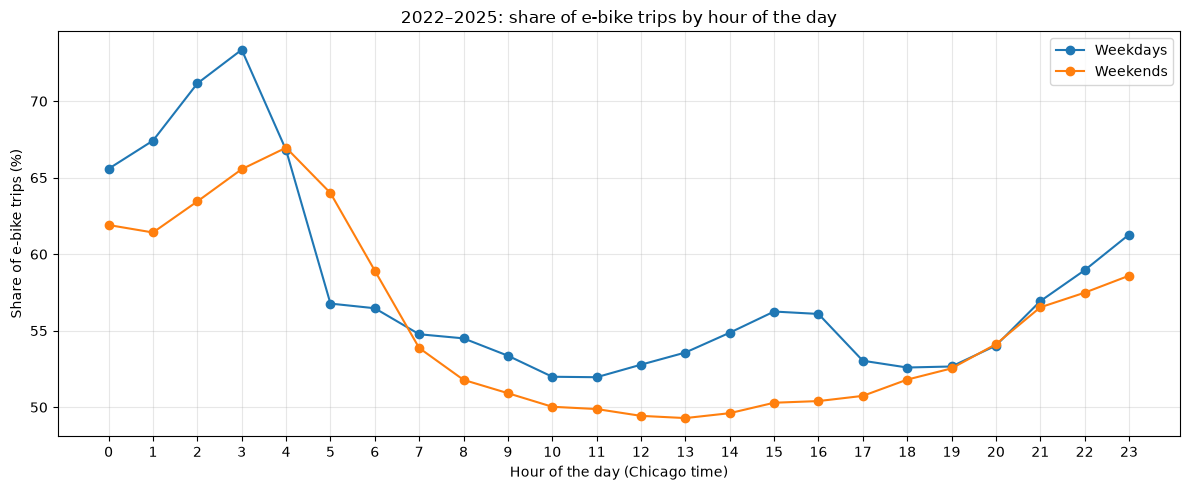

In [21]:
recent = h[h["year"].between(2022, 2025)]

fig, ax = plt.subplots(figsize=(12, 5))
for is_weekend, label in [(False, "Weekdays"), (True, "Weekends")]:
    sub = recent[recent["weekend"] == is_weekend]
    by_hour = sub.groupby(["hour_of_day", "bike_type"])["n_trips"].sum().unstack()
    ax.plot(by_hour.index, 100 * by_hour["electric"] / by_hour.sum(axis=1),
            marker="o", label=label)
ax.set_title("2022–2025: share of e-bike trips by hour of the day")
ax.set_xlabel("Hour of the day (Chicago time)")
ax.set_ylabel("Share of e-bike trips (%)")
ax.set_xticks(range(0, 24))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#### Q1b. Do e-bikes explain the extra evening trips after COVID?

➕ No: classic bikes alone go from 8.9% (2019) to 13.5% (2021) of weekday trips in the evening, so people really ride later. E-bikes add only ~1–1.6 points.
**For the model:** no effect on daily counts (only the time of day changes).

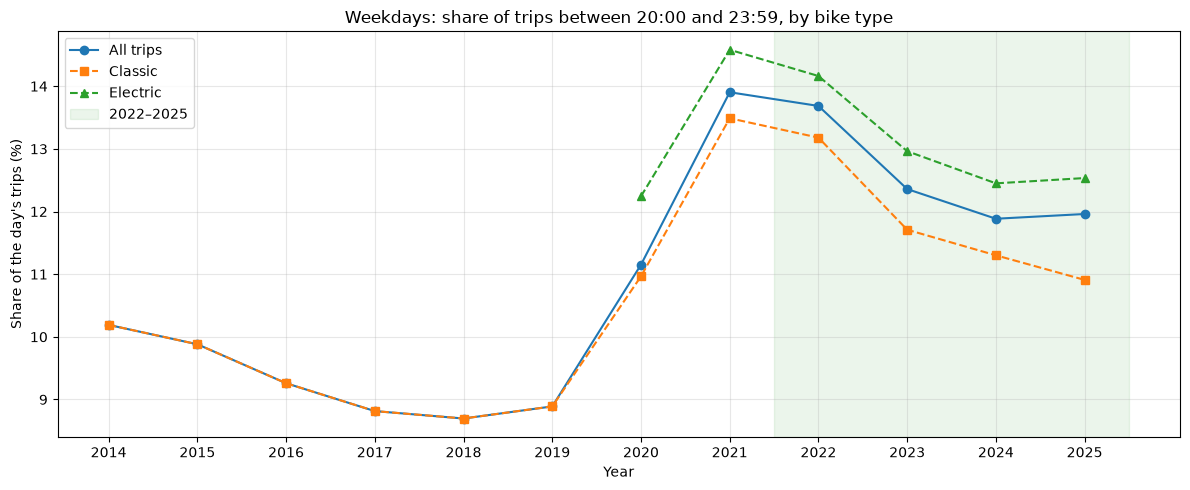

      All trips  Classic  Electric
year                              
2014       10.2     10.2       NaN
2015        9.9      9.9       NaN
2016        9.3      9.3       NaN
2017        8.8      8.8       NaN
2018        8.7      8.7       NaN
2019        8.9      8.9       NaN
2020       11.2     11.0      12.2
2021       13.9     13.5      14.6
2022       13.7     13.2      14.2
2023       12.4     11.7      13.0
2024       11.9     11.3      12.4
2025       12.0     10.9      12.5


In [22]:
weekday = h[~h["weekend"] & h["year"].between(2014, 2025)].copy()
weekday["evening"] = weekday["hour_of_day"] >= 20

def evening_share(df):
    return 100 * df.loc[df["evening"], "n_trips"].sum() / df["n_trips"].sum()

rows = []
for year, d in weekday.groupby("year"):
    row = {"year": year, "All trips": evening_share(d)}
    for bike in ["classic", "electric"]:
        sub = d[d["bike_type"] == bike]
        row[bike.capitalize()] = evening_share(sub) if len(sub) else None
    rows.append(row)
evening = pd.DataFrame(rows).set_index("year")

fig, ax = plt.subplots(figsize=(12, 5))
for col, style in [("All trips", "-o"), ("Classic", "--s"), ("Electric", "--^")]:
    ax.plot(evening.index, evening[col], style, label=col)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.08, label="2022–2025")
ax.set_title("Weekdays: share of trips between 20:00 and 23:59, by bike type")
ax.set_xlabel("Year")
ax.set_ylabel("Share of the day's trips (%)")
ax.set_xticks(evening.index)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
print(evening.round(1))

#### Q2a. Does the e-bike share depend on the season?

➕ No regular pattern: the dips and peaks fall in different months each year (e.g. Feb 2024, Jun 2022), and 2025 is ~10 points higher. Likely fleet changes (how many e-bikes are available), not the season.

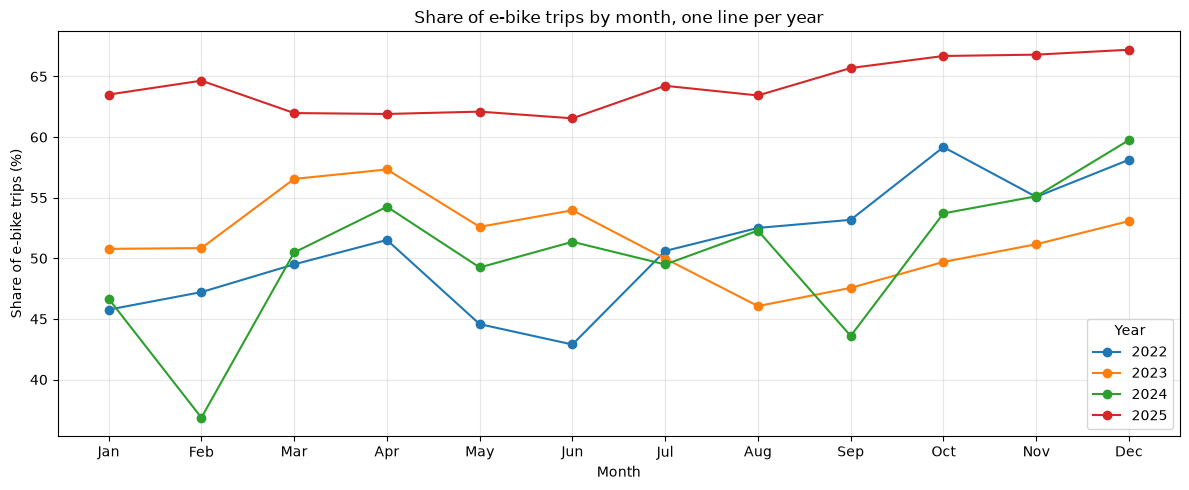

In [23]:
recent = h[h["year"].between(2022, 2025)]
by_ym = recent.groupby(["year", recent["hour"].dt.month, "bike_type"])["n_trips"].sum().unstack()
eshare = (100 * by_ym["electric"] / by_ym.sum(axis=1)).unstack(level=0)   # rows = month, columns = year

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(12, 5))
for year in eshare.columns:
    ax.plot(eshare.index, eshare[year], marker="o", label=str(year))
ax.set_title("Share of e-bike trips by month, one line per year")
ax.set_xlabel("Month")
ax.set_ylabel("Share of e-bike trips (%)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.grid(alpha=0.3)
ax.legend(title="Year")
plt.tight_layout()
plt.show()

- e-bike share jumps irregularly = they’re not caused by the season.

#### Q2b. Do e-bikes and classic bikes follow the same seasons?

➕ Yes: both go from ~2.5–3.5% of their yearly trips per month in winter to ~13.5% in July–August.
**For the model:** no separate seasonal effect per bike type, model the total.

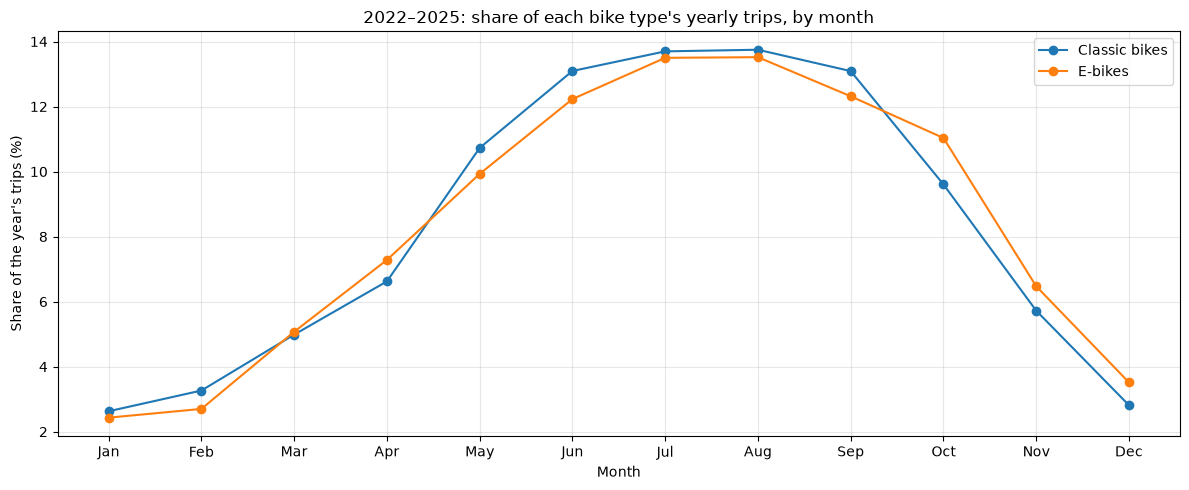

In [24]:
by_type = recent.groupby(["year", recent["hour"].dt.month, "bike_type"])["n_trips"].sum()
# share of each bike type's yearly trips that fall in each month, then averaged over 2022–2025
profile = (by_type / by_type.groupby(level=["year", "bike_type"]).transform("sum") * 100)
profile = profile.groupby(level=[1, 2]).mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
for bike, label in [("classic", "Classic bikes"), ("electric", "E-bikes")]:
    ax.plot(profile.index, profile[bike], marker="o", label=label)
ax.set_title("2022–2025: share of each bike type's yearly trips, by month")
ax.set_xlabel("Month")
ax.set_ylabel("Share of the year's trips (%)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#### Q3. Who drives the 2025 rise?

➕ Both groups: members and casual riders both jump by ~13–15 points in 2025. Not a change in who rides → more likely the fleet (more e-bikes available).

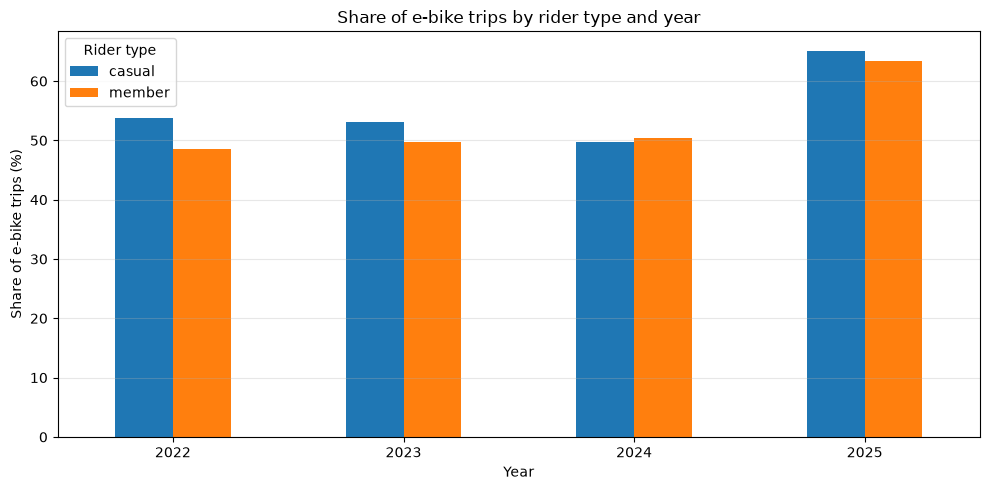

In [25]:
by_user = recent.groupby(["year", "user_type", "bike_type"])["n_trips"].sum().unstack()
share_user = (100 * by_user["electric"] / by_user.sum(axis=1)).unstack()

fig, ax = plt.subplots(figsize=(10, 5))
share_user.plot(kind="bar", ax=ax, rot=0)
ax.set_title("Share of e-bike trips by rider type and year")
ax.set_xlabel("Year")
ax.set_ylabel("Share of e-bike trips (%)")
ax.grid(alpha=0.3, axis="y")
ax.legend(title="Rider type")
plt.tight_layout()
plt.show()


#### Q4. Do e-bikes follow the same weekly rhythm?

➕ Almost: e-bikes are used slightly more on weekdays and less at weekends (weekend share 28% vs 30% for classic bikes). - As the e-bike share rises from 50% to 64%, the weekend share of all trips changes by only ~0.3 points.
**For the model:** negligible compared with the anomalies we look for.

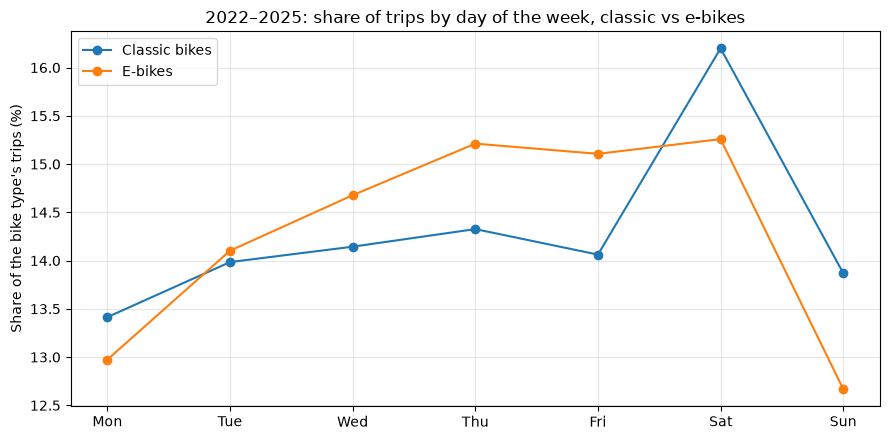

In [26]:
recent = h[h["year"].between(2022, 2025)]
by_day = recent.groupby([recent["hour"].dt.dayofweek, "bike_type"])["n_trips"].sum().unstack()
profile = 100 * by_day / by_day.sum()

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for bike, label in [("classic", "Classic bikes"), ("electric", "E-bikes")]:
    ax.plot(profile.index, profile[bike], marker="o", label=label)
ax.set_xticks(range(7))
ax.set_xticklabels(days)
ax.set_ylabel("Share of the bike type's trips (%)")
ax.set_title("2022–2025: share of trips by day of the week, classic vs e-bikes")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#### Conclusion 1.5

➕ E-bikes replace classic bikes (no extra trips) and follow the same seasons, and almost the same weekly rhythm (slightly more on weekdays).
- **For the model:** model the total number of trips for now; the weekly difference is too small to matter yet.
- **To check later:** do the two bike types react differently to the weather (rain, cold, wind), weekends and holidays, events? If yes, model them separately or add a bike type term, since the e-bike share keeps rising.
- **Limitation:** the e-bike fleet (bikes available, charged) is not in the data: a lack of e-bikes could create a small fake anomaly.

## 2. Choice of grid : day vs hour for the grid

-  Contents: 2.1 method · 2.2 Chicago's 77 zones · 2.3 day vs hour · 2.4 which zones have enough trips · 2.5 hybrid grid · 2.6 checks of the grid. 
- Why a grid: the TA warned that hours × small zones would be too sparse (fake anomalies); zones are needed to see *where* something happens (RQ c) and to detect local events, invisible in city-wide counts.

### 2.1 Method: how many trips are needed to detect an anomaly?

### 2.1 Method: how many trips are needed to detect an anomaly?

➕ A count of n trips varies by chance by about √n (Poisson), i.e. ±1/√n in relative terms: ±50% with 4 trips, ±10% with 100. To detect an anomaly of size d, roughly n > 4/d² trips are needed: ~20 trips for a 50% anomaly, ~100 for a 20% anomaly.
We compare day, 4 time blocks and hour with three arguments, all in 2.3:
1. **Theory:** share of cells below 20 and 100 trips (first plot of 2.3).
2. **Real noise:** coefficient of variation of similar cells, compared with Poisson (second plot of 2.3).
3. **Number of tests:** each cell is one test (~112,000 per day vs ~2.7 million per hour): more tests means more false alarms.
4. **For P3 (needs the model so LATER):** simulation. Add a fake anomaly (e.g. −30% of trips) to real cell-days, run the anomaly test, and count how often it is detected, per day vs per hour and for busy vs quiet cells. This measures the real detection power of each grid.

### 2.2 Chicago's 77 zones and trips per zone

#### Load and check the zones

- Goal: get Chicago's 77 community areas (City of Chicago Data Portal, GeoJSON). Result: saved in `data/external/community_areas.geojson`.

- (The download code is not in this notebook: GeoJSON file from the City of Chicago Data Portal, dataset `igwz-8jzy`.)

In [27]:
import geopandas as gpd

zones = gpd.read_file("data/external/community_areas.geojson")
print(len(zones), "zones")
print(zones.columns.tolist())
print(zones.crs)
zones.head()

77 zones
[':id', ':version', ':created_at', ':updated_at', 'area_numbe', 'community', 'area_num_1', 'shape_area', 'shape_len', 'geometry']
EPSG:4326


,:id,:version,:created_at,:updated_at,area_numbe,community,area_num_1,shape_area,shape_len,geometry
0,row-m77e_pkv8.vjvf,rv-3hjp_vkhx~fqfx,2025-04-22 23:06:36.944000+00:00,2025-04-22 23:06:36.944000+00:00,1,ROGERS PARK,1,51259902.4506,34052.3975757,"MULTIPOLYGON (((-87.65456 41.99817, -87.65574 ..."
1,row-u375_347e-y6q8,rv-tgcx_t7fr-nkkg,2025-04-22 23:06:36.944000+00:00,2025-04-22 23:06:36.944000+00:00,2,WEST RIDGE,2,98429094.8621,43020.6894583,"MULTIPOLYGON (((-87.68465 42.01948, -87.68464 ..."
2,row-kgqf-m29p-99kg,rv-bag4-8zri.nvhu,2025-04-22 23:06:36.944000+00:00,2025-04-22 23:06:36.944000+00:00,3,UPTOWN,3,65095642.7289,46972.7945549,"MULTIPOLYGON (((-87.64102 41.9548, -87.644 41...."
3,row-2dpv_pk9x-zybp,rv-82s2~rb54~emuc,2025-04-22 23:06:36.944000+00:00,2025-04-22 23:06:36.944000+00:00,4,LINCOLN SQUARE,4,71352328.2399,36624.6030848,"MULTIPOLYGON (((-87.67441 41.9761, -87.6744 41..."
4,row-37zy.7r75.56p7,rv-hrse.ahu7-rz4d,2025-04-22 23:06:36.944000+00:00,2025-04-22 23:06:36.944000+00:00,5,NORTH CENTER,5,57054167.85,31391.6697542,"MULTIPOLYGON (((-87.67336 41.93234, -87.67342 ..."


#### Tidy the zones + map

-  Goal: keep zone number, name and outline, and look at the 77 areas. Result: saved as `data/external/zones.geojson`.

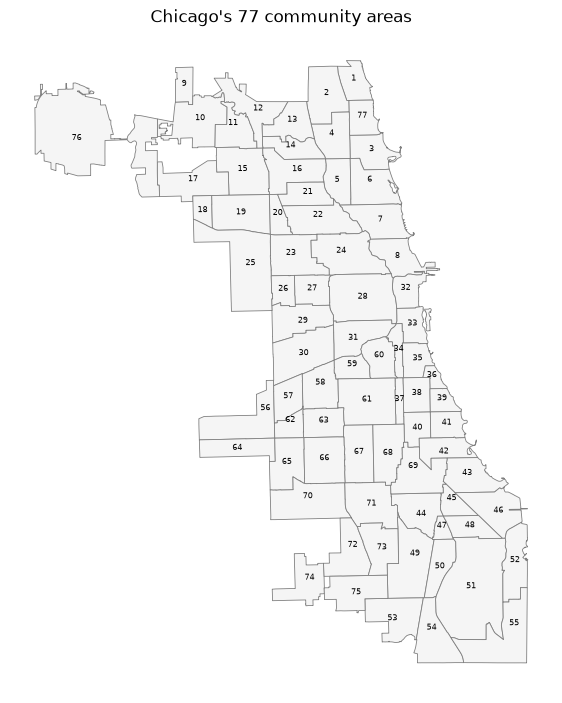

In [28]:
import matplotlib.pyplot as plt

zones = (zones[["area_numbe", "community", "geometry"]]
         .rename(columns={"area_numbe": "zone_id", "community": "zone_name"}))
zones["zone_id"] = zones["zone_id"].astype(int)
zones["zone_name"] = zones["zone_name"].str.title()          # "ROGERS PARK" -> "Rogers Park"
zones = zones.sort_values("zone_id").reset_index(drop=True)
zones.to_file("data/external/zones.geojson", driver="GeoJSON")

ax = zones.plot(figsize=(7, 9), facecolor="whitesmoke", edgecolor="grey", linewidth=0.6)
for _, z in zones.iterrows():
    p = z.geometry.representative_point()
    ax.annotate(str(z.zone_id), (p.x, p.y), ha="center", fontsize=6)
ax.set_title("Chicago's 77 community areas")
ax.set_axis_off()
plt.show()

#### Trips per hour and per zone — first version (without the 700 m rule)
- Goal: give every trip a zone and count trips per hour × zone. Result: 57,339,375 trips (matches the clean data); 1.02% start outside the 77 zones.

In [29]:
import glob
import pandas as pd

def zone_hourly_counts(zones, clean_dir="data/clean"):
    """Trips per hour and per community area (zone 0 = outside the 77 areas)."""
    parts = []
    for f in sorted(glob.glob(f"{clean_dir}/*__*.parquet")):
        df = pd.read_parquet(f, columns=["started_at", "start_lat", "start_lng",
                                         "user_type", "bike_type"])
        df["user_type"] = df["user_type"].fillna("member")      # the 190 "Dependent" trips

        # 1. place only the distinct start positions on the map
        coords = df[["start_lat", "start_lng"]].drop_duplicates()
        points = gpd.GeoDataFrame(coords, crs="EPSG:4326",
                                  geometry=gpd.points_from_xy(coords["start_lng"], coords["start_lat"]))
        joined = gpd.sjoin(points, zones[["zone_id", "geometry"]], how="left", predicate="within")
        joined = joined.drop_duplicates(subset=["start_lat", "start_lng"])   # points exactly on a border

        # 2. copy the zone back to every trip
        df = df.merge(joined[["start_lat", "start_lng", "zone_id"]],
                      on=["start_lat", "start_lng"], how="left")
        df["zone_id"] = df["zone_id"].fillna(0).astype(int)

        # 3. count per hour and zone
        df["hour"] = df["started_at"].dt.floor("h")
        df["is_casual"] = df["user_type"] == "casual"
        df["is_electric"] = df["bike_type"] == "electric"
        parts.append(df.groupby(["hour", "zone_id"]).agg(
            n_trips=("hour", "size"),
            n_casual=("is_casual", "sum"),
            n_electric=("is_electric", "sum")))
    counts = pd.concat(parts).groupby(level=[0, 1]).sum()   # some hours appear in two files
    return counts.reset_index()

zone_hourly = zone_hourly_counts(zones)
zone_hourly.to_parquet("data/zone_hourly_counts.parquet")

print(len(zone_hourly), "rows,", zone_hourly["n_trips"].sum(), "trips")
outside = zone_hourly.loc[zone_hourly["zone_id"] == 0, "n_trips"].sum()
print("Outside the 77 zones:", outside, f"({100 * outside / zone_hourly['n_trips'].sum():.2f}%)")
zone_hourly.head()

2789253 rows, 57339375 trips
Outside the 77 zones: 586222 (1.02%)


,hour,zone_id,n_trips,n_casual,n_electric
0,2013-06-27 01:00:00,28,1,0,0
1,2013-06-27 11:00:00,24,1,0,0
2,2013-06-27 11:00:00,28,3,0,0
3,2013-06-27 12:00:00,7,1,0,0
4,2013-06-27 12:00:00,8,2,1,0


#### Where are the trips outside the 77 zones?
- Goal: understand the 1.02%. 
- Result: 0% before 2016, then rising (0.5% → 1.8%). Two groups: Evanston (Divvy stations from 2016, e.g. Northwestern University) and points just outside the outlines (lakefront, city limits).

      outside  share_%
year                  
2013      0.0     0.00
2014      0.0     0.00
2015      0.0     0.00
2016  18254.0     0.51
2017  27341.0     0.71
2018  22939.0     0.64
2019  23958.0     0.63
2020  29578.0     0.85
2021  58494.0     1.06
2022  69409.0     1.25
2023  72702.0     1.31
2024  83980.0     1.47
2025  92089.0     1.71
2026  87478.0     1.79

July 2024, outside trips: 11963
start_station_name
(no station)                      9226
Benson Ave & Church St             667
Chicago Ave & Sheridan Rd          360
Chicago Ave & Washington St        330
Sheridan Rd & Noyes St (NU)        314
University Library (NU)            197
Evanston Civic Center              159
Central St Metra                   142
Central St & Girard Ave            131
Lincolnwood Dr & Central St         83
Dodge Ave & Church St               74
Elmwood Ave & Austin St             73
Valli Produce - Evanston Plaza      72
Dodge Ave & Main St                 66
Dodge Ave & Mulford St            

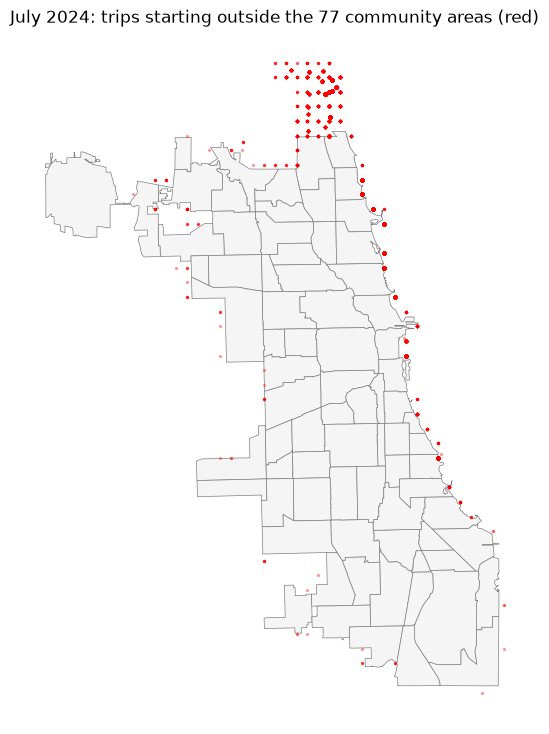

In [30]:
# 1. Outside trips per year
zh = zone_hourly.copy()
zh["year"] = zh["hour"].dt.year
per_year = zh.groupby("year").apply(
    lambda d: pd.Series({"outside": d.loc[d["zone_id"] == 0, "n_trips"].sum(),
                         "share_%": 100 * d.loc[d["zone_id"] == 0, "n_trips"].sum() / d["n_trips"].sum()}))
print(per_year.round(2))

# 2. Where: the main outside start points, in one summer month (July 2024)
f = [p for p in glob.glob("data/clean/*__*.parquet") if "202407" in p][0]
df = pd.read_parquet(f, columns=["start_lat", "start_lng", "start_station_name"])
pts = gpd.GeoDataFrame(df, crs="EPSG:4326",
                       geometry=gpd.points_from_xy(df["start_lng"], df["start_lat"]))
pts = gpd.sjoin(pts, zones[["zone_id", "geometry"]], how="left", predicate="within")
out = pts[pts["zone_id"].isna()]
print("\nJuly 2024, outside trips:", len(out))
print(out["start_station_name"].fillna("(no station)").value_counts().head(15))

# 3. Map
ax = zones.plot(figsize=(7, 9), facecolor="whitesmoke", edgecolor="grey", linewidth=0.5)
out.plot(ax=ax, markersize=2, color="red", alpha=0.3)
ax.set_title("July 2024: trips starting outside the 77 community areas (red)")
ax.set_axis_off()
plt.show()

#### 700 m rule: test on July 2024
- Goal: give positions just outside the outlines to the nearest zone if it is within 700 m (maximum rounding error of e-bike positions). 
- Result: 7,776 of 11,963 outside trips moved to a zone; the 4,187 left are almost all in Evanston.
- Limitation: a few trips from the southern edge of Evanston may be counted in Rogers Park.

Outside trips, July 2024: 11963
Moved to the nearest zone (≤ 700 m): 7776
Still outside: 4187


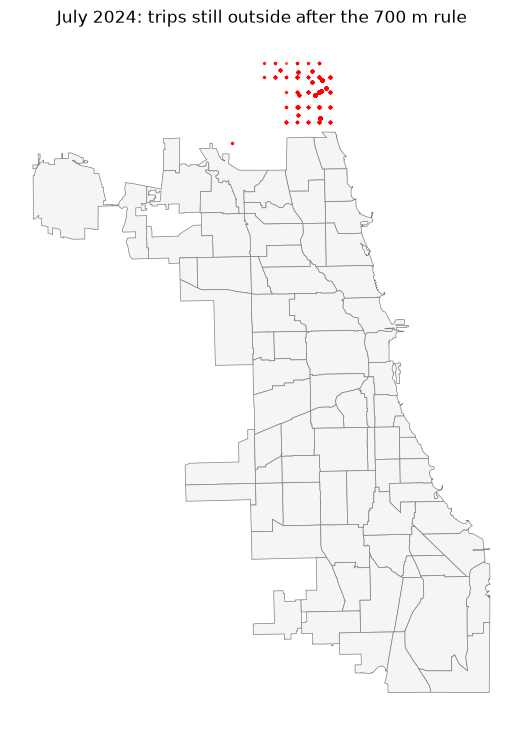

In [31]:
zones_m = zones.to_crs(epsg=26916)   # metric coordinates (UTM 16N), so distances are in metres

out_m = out[["start_lat", "start_lng", "start_station_name", "geometry"]].to_crs(epsg=26916)
near = gpd.sjoin_nearest(out_m, zones_m[["zone_id", "geometry"]], how="left",
                         max_distance=700, distance_col="dist_m")
near = near[~near.index.duplicated()]

print("Outside trips, July 2024:", len(out))
print("Moved to the nearest zone (≤ 700 m):", near["zone_id"].notna().sum())
print("Still outside:", near["zone_id"].isna().sum())

ax = zones.plot(figsize=(7, 9), facecolor="whitesmoke", edgecolor="grey", linewidth=0.5)
still_out = out.loc[near.index[near["zone_id"].isna()]]
still_out.plot(ax=ax, markersize=2, color="red", alpha=0.3)
ax.set_title("July 2024: trips still outside after the 700 m rule")
ax.set_axis_off()
plt.show()

#### Outside trips by bike type (July 2024)

- check that there is no classical bike not at a station

In [32]:
df = pd.read_parquet(f, columns=["start_lat", "start_lng", "start_station_name", "bike_type"])
pts = gpd.GeoDataFrame(df, crs="EPSG:4326",
                       geometry=gpd.points_from_xy(df["start_lng"], df["start_lat"]))
pts = gpd.sjoin(pts, zones[["zone_id", "geometry"]], how="left", predicate="within")
out = pts[pts["zone_id"].isna()].copy()
out["has_station"] = out["start_station_name"].notna()
print(pd.crosstab(out["bike_type"], out["has_station"], margins=True))

has_station  False  True    All
bike_type                      
classic          0  1625   1625
electric      9226  1112  10338
All           9226  2737  11963


#### 700 m rule on other years (July 2022, 2023, 2025)

- check that the rule also works outside July 2024 : yes work
- count the trips moved to Rogers Park (zone 1, next to Evanston) : At most ~280–350 trips per month are moved to Rogers Park (zone 1, next to Evanston), part of them real Rogers Park lakefront trips: negligible.
- count the trips per day left outside (mainly Evanston) : ~3,850–4,350 per month stay outside, mainly Evanston (~125–140 trips per day in July, fewer in winter: too few for a zone of its own, so Evanston is left out).
- Decision : trips starting in Evanston, less than 1% of trips, are left out of the zone analysis. zone 0 = outside, not analysed
- ASKKKK

202207: 804385 trips | outside 10938 | moved 6597 (of which to Rogers Park: 276) | still outside 4341 (~140 per day)
202307: 746412 trips | outside 11973 | moved 8122 (of which to Rogers Park: 318) | still outside 3851 (~124 per day)
202507: 738793 trips | outside 13917 | moved 9566 (of which to Rogers Park: 346) | still outside 4351 (~140 per day)


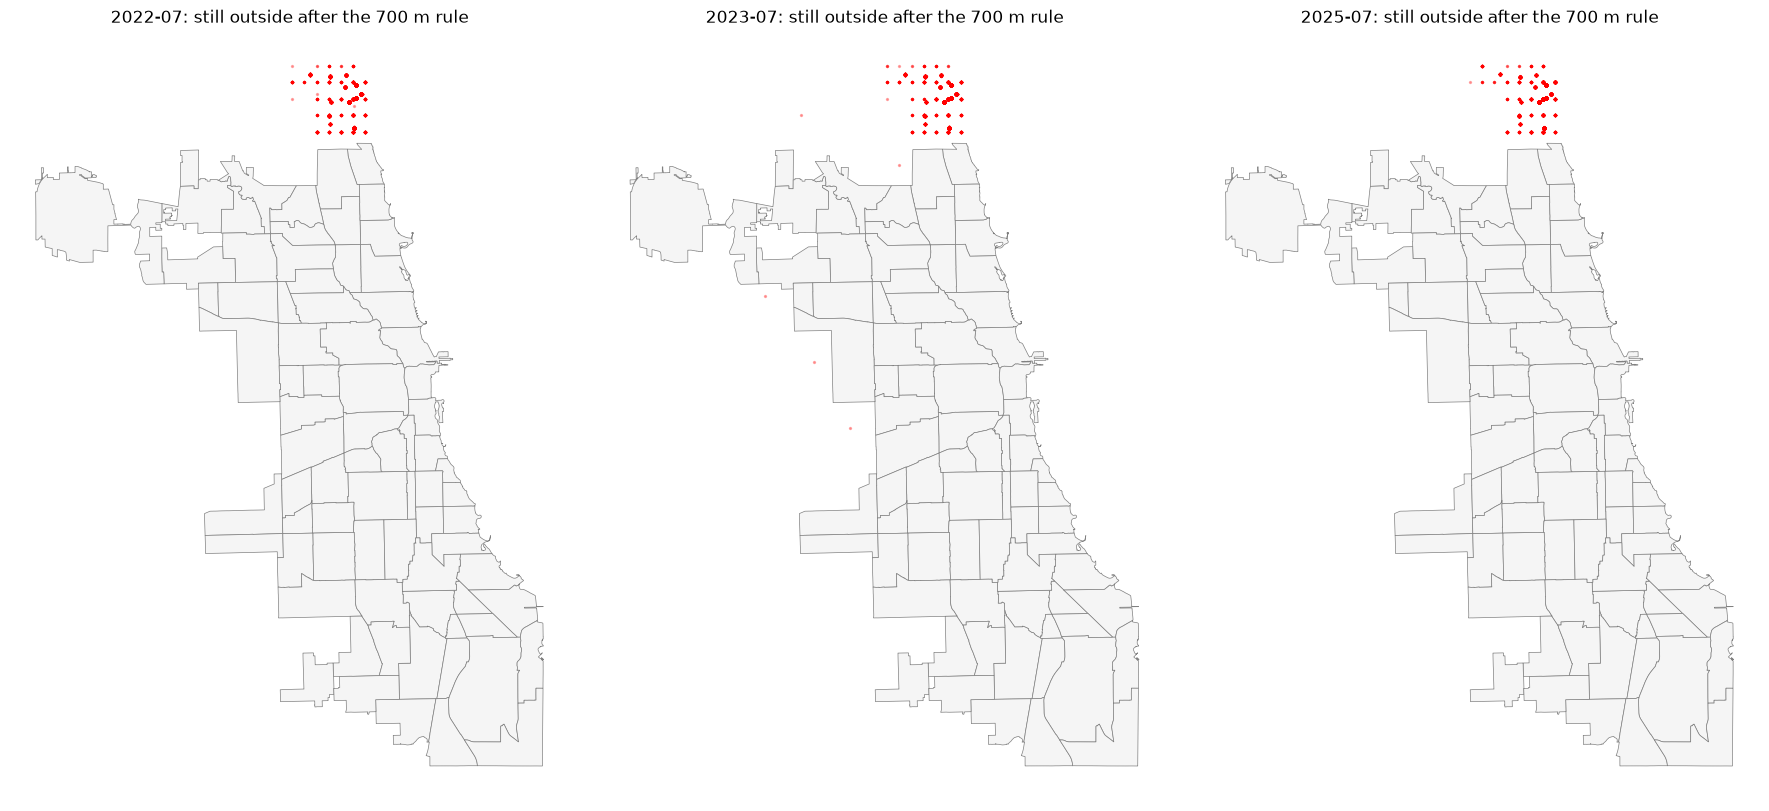

In [33]:
zones_m = zones.to_crs(epsg=26916)
months = ["202207", "202307", "202507"]

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, month in zip(axes, months):
    f_m = [p for p in glob.glob("data/clean/*__*.parquet") if month in p][0]
    d = pd.read_parquet(f_m, columns=["start_lat", "start_lng"])
    p_ = gpd.GeoDataFrame(d, crs="EPSG:4326",
                          geometry=gpd.points_from_xy(d["start_lng"], d["start_lat"]))
    p_ = gpd.sjoin(p_, zones[["zone_id", "geometry"]], how="left", predicate="within")
    p_ = p_[~p_.index.duplicated()]
    o = p_[p_["zone_id"].isna()].drop(columns=["index_right", "zone_id"])

    n = gpd.sjoin_nearest(o.to_crs(epsg=26916), zones_m[["zone_id", "geometry"]],
                          how="left", max_distance=700)
    n = n[~n.index.duplicated()]
    still = o.loc[n.index[n["zone_id"].isna()]]

    print(f"{month}: {len(d)} trips | outside {len(o)} | moved {n['zone_id'].notna().sum()} "
          f"(of which to Rogers Park: {(n['zone_id'] == 1).sum()}) | still outside {len(still)} "
          f"(~{len(still) / 31:.0f} per day)")

    zones.plot(ax=ax, facecolor="whitesmoke", edgecolor="grey", linewidth=0.5)
    still.plot(ax=ax, markersize=2, color="red", alpha=0.3)
    ax.set_title(f"{month[:4]}-{month[4:]}: still outside after the 700 m rule")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

#### Trips per hour and per zone — final version (with the 700 m rule)

- recount trips per hour × zone, giving positions just outside the outlines to the nearest zone within 700 m; zone 0 = outside Chicago (mainly Evanston, left out of the zone analysis). 
- Result: 57,339,375 trips (matches the clean data). Outside: 0.64% of trips (1.02% without the rule): 0% before 2016 (no Evanston stations yet), then about 0.6–0.9% per year.
- saved in `data/zone_hourly_counts.parquet`. 

In [34]:
zones_m = zones.to_crs(epsg=26916)

def zone_hourly_counts(zones, zones_m, clean_dir="data/clean", max_dist_m=700):
    """Trips per hour and per community area.

    A start position outside every area is given to the nearest area if it is within
    max_dist_m (e-bike positions are rounded to ~1 km); otherwise zone 0 = outside (mainly Evanston).
    """
    parts = []
    for f in sorted(glob.glob(f"{clean_dir}/*__*.parquet")):
        df = pd.read_parquet(f, columns=["started_at", "start_lat", "start_lng",
                                         "user_type", "bike_type"])
        df["user_type"] = df["user_type"].fillna("member")      # the 190 "Dependent" trips

        # 1. place only the distinct start positions on the map
        coords = df[["start_lat", "start_lng"]].drop_duplicates().reset_index(drop=True)
        points = gpd.GeoDataFrame(coords, crs="EPSG:4326",
                                  geometry=gpd.points_from_xy(coords["start_lng"], coords["start_lat"]))
        joined = gpd.sjoin(points, zones[["zone_id", "geometry"]], how="left", predicate="within")
        joined = joined[~joined.index.duplicated()]

        # 2. positions outside every zone: nearest zone within max_dist_m
        missing = joined.index[joined["zone_id"].isna()]
        if len(missing) > 0:
            near = gpd.sjoin_nearest(points.loc[missing].to_crs(epsg=26916),
                                     zones_m[["zone_id", "geometry"]],
                                     how="left", max_distance=max_dist_m)
            near = near[~near.index.duplicated()]
            joined.loc[near.index, "zone_id"] = near["zone_id"].values

        # 3. copy the zone back to every trip
        df = df.merge(joined[["start_lat", "start_lng", "zone_id"]],
                      on=["start_lat", "start_lng"], how="left")
        df["zone_id"] = df["zone_id"].fillna(0).astype(int)

        # 4. count per hour and zone
        df["hour"] = df["started_at"].dt.floor("h")
        df["is_casual"] = df["user_type"] == "casual"
        df["is_electric"] = df["bike_type"] == "electric"
        parts.append(df.groupby(["hour", "zone_id"]).agg(
            n_trips=("hour", "size"),
            n_casual=("is_casual", "sum"),
            n_electric=("is_electric", "sum")))
    counts = pd.concat(parts).groupby(level=[0, 1]).sum()
    return counts.reset_index()

zone_hourly = zone_hourly_counts(zones, zones_m)
zone_hourly.to_parquet("data/zone_hourly_counts.parquet")

zh = zone_hourly.assign(year=zone_hourly["hour"].dt.year)
outside = zh[zh["zone_id"] == 0].groupby("year")["n_trips"].sum()
share = (100 * outside / zh.groupby("year")["n_trips"].sum()).round(2)
print(zone_hourly["n_trips"].sum(), "trips,", len(zone_hourly), "rows")
print(pd.DataFrame({"outside": outside, "share_%": share}).fillna(0))

57339375 trips, 2793484 rows
      outside  share_%
year                  
2013      0.0     0.00
2014      0.0     0.00
2015      0.0     0.00
2016  16636.0     0.46
2017  25800.0     0.67
2018  22090.0     0.61
2019  22625.0     0.59
2020  25062.0     0.72
2021  36196.0     0.66
2022  38915.0     0.70
2023  39749.0     0.71
2024  45460.0     0.79
2025  49504.0     0.92
2026  44396.0     0.91


### 2.3 Day vs hour

#### Trips per cell: day, 4 time blocks, hour (real zones, 2022–2025)
➕ A cell = one zone × one time period (a day, a time block or an hour): the unit in which we count trips and look for anomalies

- Per hour, almost all cells are too sparse: the hour is ruled out. 
- Per day it is much better, but ~60% of zone-days still have fewer than 20 trips.

               number of cells (= tests)  median trips per cell  \
resolution                                                        
Day                               112497                    9.0   
4 time blocks                     449988                    2.0   
Hour                             2699928                    0.0   

               % cells with 0 trips  % cells < 20 trips  % cells < 100 trips  
resolution                                                                    
Day                            12.3                62.3                 79.2  
4 time blocks                  33.7                79.7                 91.0  
Hour                           60.0                91.9                 97.8  


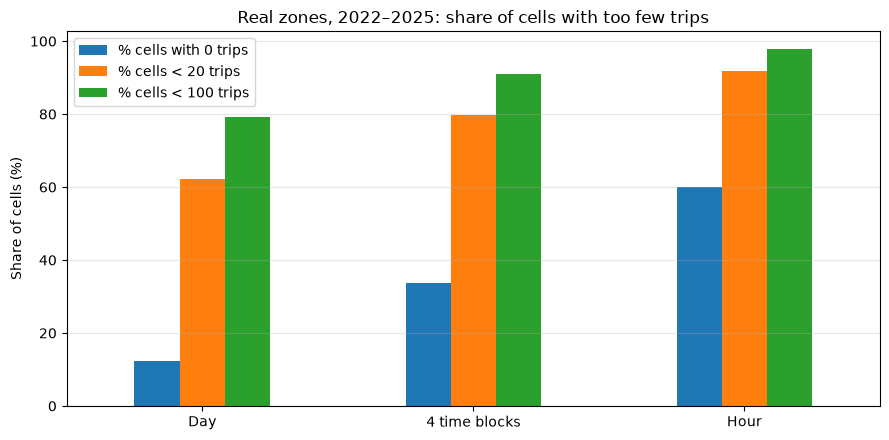

In [35]:
import numpy as np

zh = pd.read_parquet("data/zone_hourly_counts.parquet")
zh = zh[(zh["zone_id"] > 0) & zh["hour"].dt.year.between(2022, 2025)]

# add the zone-hours with 0 trips
all_hours = pd.date_range("2022-01-01 00:00", "2025-12-31 23:00", freq="h")
grid = pd.MultiIndex.from_product([all_hours, range(1, 78)], names=["hour", "zone_id"])
full = (zh.set_index(["hour", "zone_id"])["n_trips"]
          .reindex(grid, fill_value=0)
          .reset_index())
full["date"] = full["hour"].dt.normalize()
full["block"] = pd.cut(full["hour"].dt.hour, bins=[0, 6, 10, 16, 24], right=False,
                       labels=["night", "morning", "midday", "evening"])
full["hour_of_day"] = full["hour"].dt.hour

cells = {
    "Day": full.groupby(["zone_id", "date"])["n_trips"].sum().reset_index(),
    "4 time blocks": full.groupby(["zone_id", "date", "block"], observed=True)["n_trips"].sum().reset_index(),
    "Hour": full[["zone_id", "date", "hour_of_day", "n_trips"]],
}

rows = []
for name, c in cells.items():
    rows.append({"resolution": name,
                 "number of cells (= tests)": len(c),
                 "median trips per cell": c["n_trips"].median(),
                 "% cells with 0 trips": 100 * (c["n_trips"] == 0).mean(),
                 "% cells < 20 trips": 100 * (c["n_trips"] < 20).mean(),
                 "% cells < 100 trips": 100 * (c["n_trips"] < 100).mean()})
sparsity = pd.DataFrame(rows).set_index("resolution").round(1)
print(sparsity)

fig, ax = plt.subplots(figsize=(9, 4.5))
sparsity[["% cells with 0 trips", "% cells < 20 trips", "% cells < 100 trips"]].plot(kind="bar", ax=ax, rot=0)
ax.set_title("Real zones, 2022–2025: share of cells with too few trips")
ax.set_ylabel("Share of cells (%)")
ax.set_xlabel("")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

#### Noise of the counts (coefficient of variation)

- **What we measure:** days that should look alike (same zone, same month, same type of day) still differ by chance. The CV says by how much (CV = 0.5 → they differ by ~50%).
-  **What we see:** per day the noise is lower (box at ~0.5) than per hour (box at ~1.3).
-  **Conclusion:** per hour the noise is too big to see any anomaly → we use days.
- **Extra (table):** (Poisson = the noise we'd get by pure chance), per hour the noise is pure chance (real ≈ Poisson); per day there is more than chance (real / Poisson ≈ 1.4): real differences between days, which the model can explain.

               median CV (real)  median CV (Poisson)  real / Poisson
Day                        0.47                 0.33            1.44
4 time blocks              0.76                 0.66            1.20
Hour                       1.34                 1.25            1.06


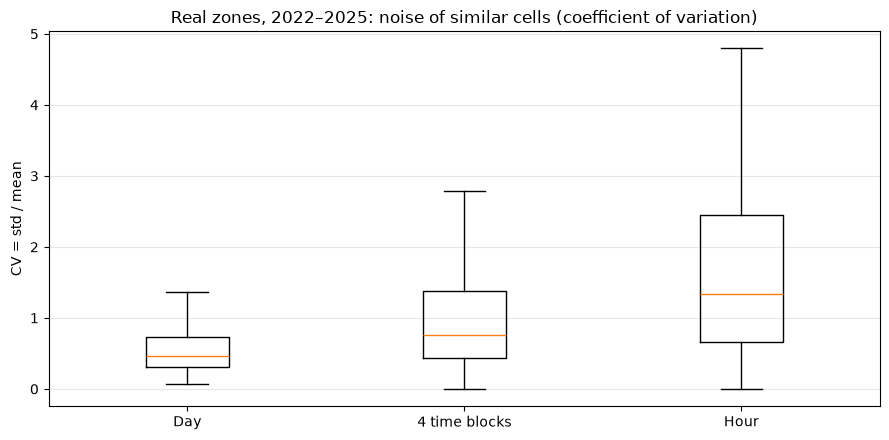

In [36]:
def cv_per_group(c, slot=None):
    """CV of counts across similar cells: same zone, month, weekday/weekend (and time slot)."""
    d = c.copy()
    d["month"] = d["date"].dt.to_period("M")
    d["weekend"] = d["date"].dt.dayofweek >= 5
    keys = ["zone_id", "month", "weekend"] + ([slot] if slot else [])
    g = d.groupby(keys, observed=True)["n_trips"].agg(["mean", "std"])
    g = g[g["mean"] > 0]
    g["cv"] = g["std"] / g["mean"]
    g["cv_poisson"] = 1 / np.sqrt(g["mean"])
    return g

cv = {"Day": cv_per_group(cells["Day"]),
      "4 time blocks": cv_per_group(cells["4 time blocks"], slot="block"),
      "Hour": cv_per_group(cells["Hour"], slot="hour_of_day")}

summary = pd.DataFrame({name: {"median CV (real)": g["cv"].median(),
                               "median CV (Poisson)": g["cv_poisson"].median(),
                               "real / Poisson": (g["cv"] / g["cv_poisson"]).median()}
                        for name, g in cv.items()}).T.round(2)
print(summary)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([g["cv"].dropna() for g in cv.values()], tick_labels=list(cv.keys()), showfliers=False)
ax.set_title("Real zones, 2022–2025: noise of similar cells (coefficient of variation)")
ax.set_ylabel("CV = std / mean")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### 2.4 Which zones have enough trips per day?

- Goal: for each zone, the median trips per day (left) and the share of days with at least 20 trips (2022–2025) (right), to see which zones can be analysed per day. 
- Result: very unequal city. Downtown and the north lakefront have 126–2,775 trips per day; most of the South Side, the far West and the far north-west have 0–17. 
- With 77 separate zones, the South and West Sides would be blind spots, so quiet zones must be merged or handled separately.

Zones with ≥ 20 trips on at least 90% of days: 20
Zones with ≥ 20 trips on at least 90% of summer days: 28


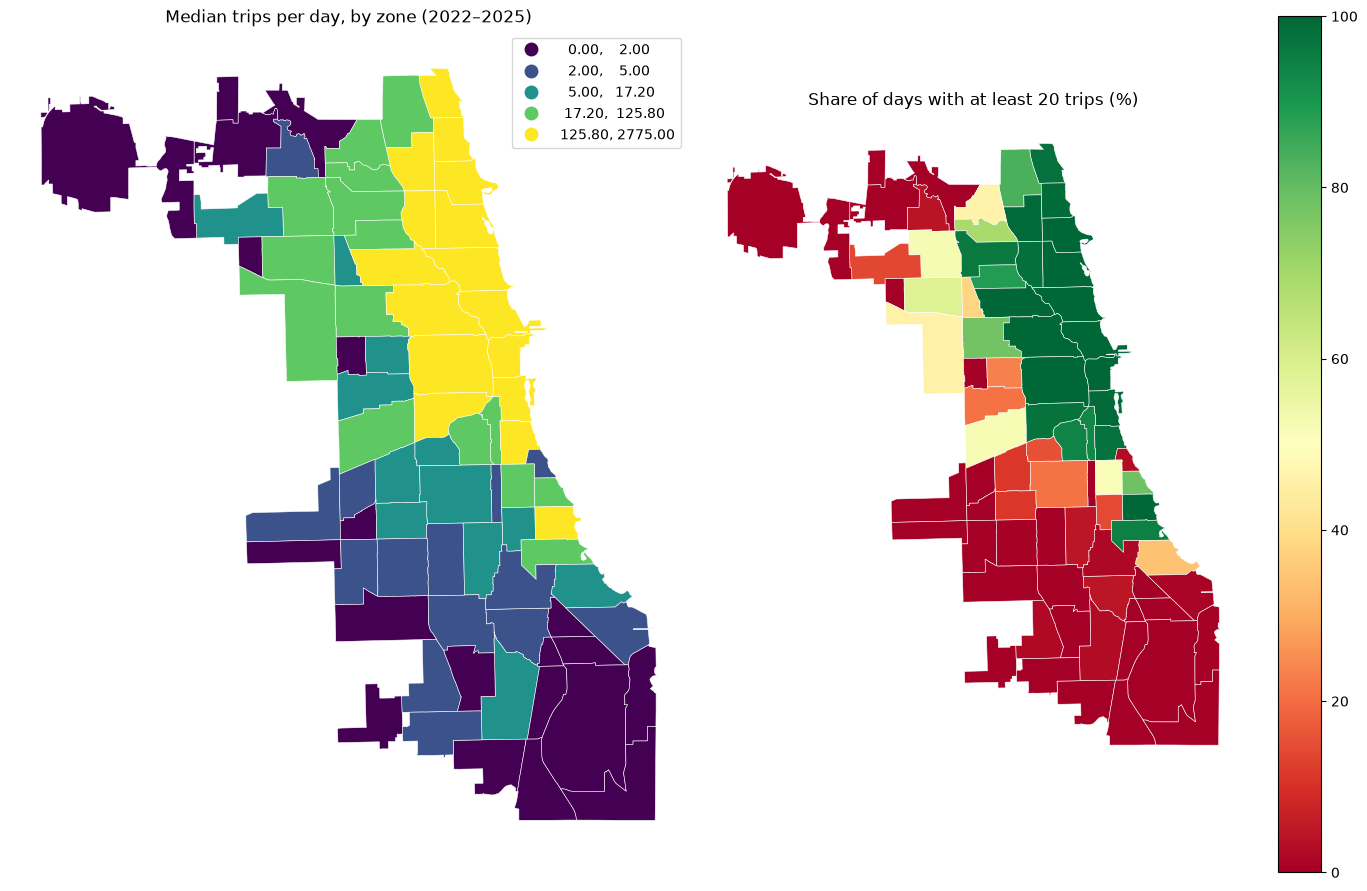

In [37]:
day = cells["Day"].copy()
day["summer"] = day["date"].dt.month.isin([6, 7, 8])

per_zone = day.groupby("zone_id").agg(
    median_trips_per_day=("n_trips", "median"),
    pct_days_20plus=("n_trips", lambda s: 100 * (s >= 20).mean()))
per_zone["pct_summer_days_20plus"] = day[day["summer"]].groupby("zone_id")["n_trips"].apply(
    lambda s: 100 * (s >= 20).mean())
per_zone = zones.merge(per_zone, left_on="zone_id", right_index=True)

print("Zones with ≥ 20 trips on at least 90% of days:", (per_zone["pct_days_20plus"] >= 90).sum())
print("Zones with ≥ 20 trips on at least 90% of summer days:", (per_zone["pct_summer_days_20plus"] >= 90).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
per_zone.plot(column="median_trips_per_day", ax=axes[0], legend=True, cmap="viridis",
              scheme="quantiles", k=5, edgecolor="white", linewidth=0.4)
axes[0].set_title("Median trips per day, by zone (2022–2025)")
per_zone.plot(column="pct_days_20plus", ax=axes[1], legend=True, cmap="RdYlGn",
              vmin=0, vmax=100, edgecolor="white", linewidth=0.4)
axes[1].set_title("Share of days with at least 20 trips (%)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

 - Left: the typical number of trips per day (the median).
- Right: how often the zone is “usable” (≥ 20 trips)

### 2.5 Hybrid grid

Options considered: 
- A. 77 zones, test only busy zone-days (South and West Sides would be blind spots); 
- B. hybrid: busy zones alone, neighbouring quiet zones merged (chosen); 
- C. about 9 big areas (but too coarse downtown). 

The grid is saved as a table `zone_id → cell_id` (`data/zone_to_cell.csv`):

#### First version Hybrid grid (one option).** 

- Goal: keep busy zones separate and merge neighbouring quiet zones until every cell has ≥ 20 trips on ≥ 90% of days (2022–2025), so no cell is too sparse (TA feedback) and the whole city is covered.

Result: 
- 25 cells (19 single zones, 6 groups)
- cell-days with ≥ 20 trips go from 38% (77 zones) to 98%.
- But one group covers 30 areas (almost the whole South Side), because winter days have very few trips, and some quiet groups were merged into groups already above the target. Too coarse.

/opt/homebrew/anaconda3/envs/ada/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/homebrew/anaconda3/envs/ada/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


Note: quiet group 43 merged into a busy zone (Mount Greenwood)
Note: quiet group 2 merged into a busy zone (Albany Park)
Note: quiet group 21 merged into a busy zone (Irving Park)
Cells: 25 | single zones: 19 | merged groups: 6
  Group 2: West Ridge, Albany Park, North Park, Montclare, Dunning, Jefferson Park, Forest Glen, Ohare, Edison Park, Norwood Park
  Group 9: Humboldt Park, Portage Park, Belmont Cragin
  Group 10: Avondale, Irving Park
  Group 11: South Lawndale, Mckinley Park, Archer Heights, Garfield Ridge, Brighton Park, North Lawndale, West Garfield Park, East Garfield Park, Hermosa, Austin
  Group 20: Oakland, Grand Boulevard, Kenwood
  Group 21: South Shore, Roseland, Chatham, East Side, South Chicago, Avalon Park, Burnside, Calumet Heights, South Deering, Greater Grand Crossing, Mount Greenwood, Beverly, Clearing, West Elsdon, Ashburn, West Lawn, Gage Park, New City, Washington Park, Fuller Park, Englewood, Chicago Lawn, West Englewood, Auburn Gresham, Washington Heights,

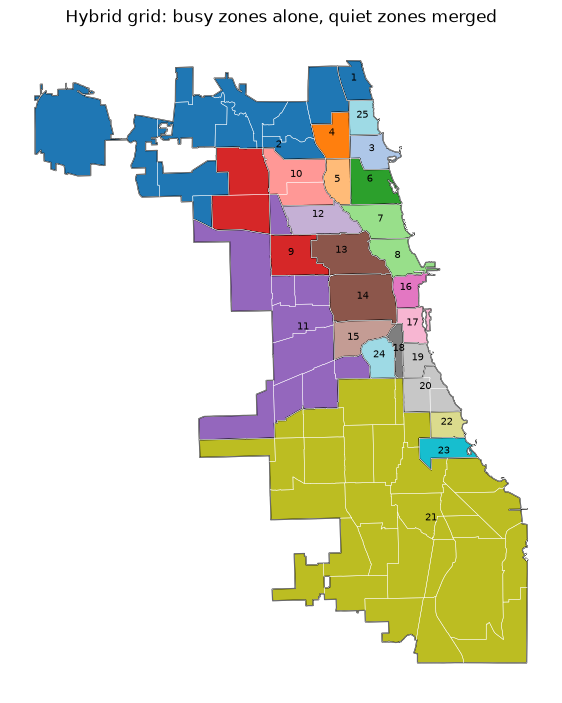

In [38]:
zm = zones.to_crs(epsg=26916).set_index("zone_id")
zone_name = zones.set_index("zone_id")["zone_name"]

# daily trips: one row per day, one column per zone (from the "Day" cells, zeros included)
daily = cells["Day"].pivot(index="date", columns="zone_id", values="n_trips").fillna(0)

def pct_days_ok(zone_list, min_trips=20):
    """% of days on which the zones together have at least min_trips trips."""
    return 100 * (daily[zone_list].sum(axis=1) >= min_trips).mean()

# neighbours = zones whose outlines touch (5 m tolerance)
geom = zm.geometry.buffer(5)
neighbours = {z: set(zm.index[geom.intersects(geom[z])]) - {z} for z in zm.index}

TARGET = 90                          # % of days with ≥ 20 trips
groups = {z: [z] for z in zm.index}  # start: every zone is its own group

def group_of(z):
    return next(g for g, members in groups.items() if z in members)

while True:
    scores = {g: pct_days_ok(m) for g, m in groups.items()}
    failing = {g: s for g, s in scores.items() if s < TARGET}
    if not failing:
        break
    g = min(failing, key=failing.get)                                  # the quietest group
    nb = {group_of(n) for z in groups[g] for n in neighbours[z]} - {g}  # its neighbouring groups
    candidates = [h for h in nb if h in failing] or list(nb)           # prefer quiet neighbours
    if not candidates:
        print("No neighbour for group", g)
        break
    h = min(candidates, key=lambda k: daily[groups[k]].values.sum())  # the neighbour with fewest trips
    if h not in failing:
        print(f"Note: quiet group {g} merged into a busy zone ({zone_name[groups[h][0]]})")
    groups[g] += groups.pop(h)

# table zone_id -> cell_id
rows = []
for k, members in enumerate(sorted(groups.values(), key=min), start=1):
    name = zone_name[members[0]] if len(members) == 1 else f"Group {k} ({len(members)} areas)"
    for z in members:
        rows.append({"zone_id": z, "cell_id": k, "cell_name": name})
zone_to_cell = pd.DataFrame(rows)
zone_to_cell.to_csv("data/zone_to_cell.csv", index=False)

# summary
sizes = zone_to_cell.groupby("cell_id").size()
print("Cells:", len(sizes), "| single zones:", (sizes == 1).sum(), "| merged groups:", (sizes > 1).sum())
for k, members in zone_to_cell[zone_to_cell["cell_id"].isin(sizes[sizes > 1].index)].groupby("cell_id"):
    print(f"  Group {k}: {', '.join(zone_name[members['zone_id']])}")

# option A vs option B
cell_daily = daily.T.groupby(zone_to_cell.set_index("zone_id")["cell_id"]).sum().T
print(f"\nCell-days with ≥ 20 trips: A (77 zones) {100 * (daily >= 20).values.mean():.0f}% "
      f"| B (hybrid) {100 * (cell_daily >= 20).values.mean():.0f}%")

# map
cells_map = zones.merge(zone_to_cell, on="zone_id").dissolve(by="cell_id").reset_index()
ax = cells_map.plot(figsize=(7, 9), column="cell_id", cmap="tab20", edgecolor="black", linewidth=0.8)
zones.boundary.plot(ax=ax, color="white", linewidth=0.3)
for _, c in cells_map.iterrows():
    p = c.geometry.representative_point()
    ax.annotate(str(c.cell_id), (p.x, p.y), ha="center", fontsize=7)
ax.set_title("Hybrid grid: busy zones alone, quiet zones merged")
ax.set_axis_off()
plt.show()

#### Second version: target on April–October (final grid)

Changes: 
- The target only counts April–October days (far fewer trips in winter)
-  no merging into groups already above the target, fixed zone outlines (`make_valid`).
 Result: 
 - 37 cells (28 single zones, 9 merged groups);
 - the South Side is split into 4 groups instead of 1.
 -  85% of cell-days have ≥ 20 trips over the whole year (38% with 77 zones). 
 - 4 cells stay just below the target (South Shore, North Park, South Lawndale, Oakland + Grand Boulevard). 
 
 Limitation: some southern groups are large (up to 12 areas).
 
 Saved as `data/zone_to_cell.csv`.

/opt/homebrew/anaconda3/envs/ada/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/homebrew/anaconda3/envs/ada/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


Below target, no quiet neighbour: South Shore (56% of Apr–Oct days)
Below target, no quiet neighbour: Oakland, Grand Boulevard (90% of Apr–Oct days)
Below target, no quiet neighbour: North Park (72% of Apr–Oct days)
Below target, no quiet neighbour: South Lawndale (78% of Apr–Oct days)
Cells: 37 | single zones: 28 | merged groups: 9
  Group 9: Montclare, Dunning, Jefferson Park, Forest Glen, Ohare, Edison Park, Norwood Park
  Group 12: Portage Park, Belmont Cragin
  Group 14: Hermosa, Austin
  Group 19: North Lawndale, West Garfield Park, East Garfield Park
  Group 27: Oakland, Grand Boulevard
  Group 28: Washington Park, Fuller Park, Englewood, Chicago Lawn, West Englewood, Auburn Gresham, Washington Heights, Morgan Park, Pullman, West Pullman, Riverdale, Hegewisch
  Group 33: Roseland, Chatham, East Side, South Chicago, Avalon Park, Burnside, Calumet Heights, South Deering, Greater Grand Crossing
  Group 34: Mckinley Park, Archer Heights, Garfield Ridge, Brighton Park
  Group 36: Mou

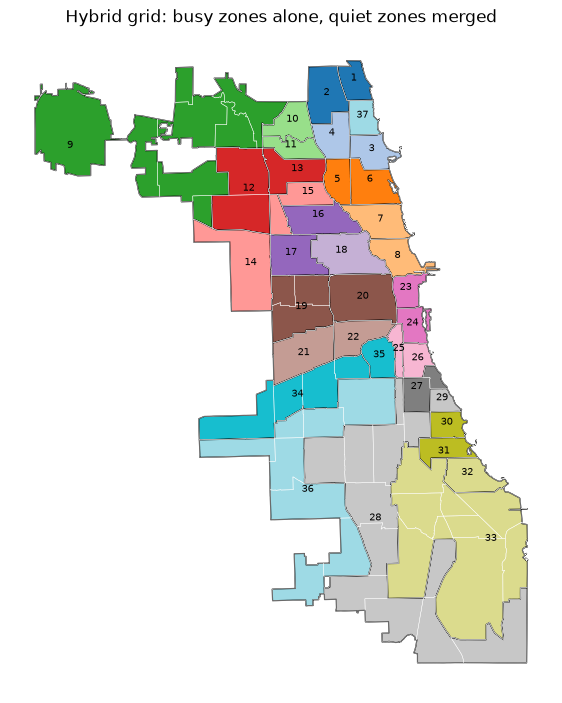

In [39]:
zm = zones.to_crs(epsg=26916).set_index("zone_id")
zone_name = zones.set_index("zone_id")["zone_name"]

# daily trips: one row per day, one column per zone (from the "Day" cells, zeros included)
daily = cells["Day"].pivot(index="date", columns="zone_id", values="n_trips").fillna(0)

def pct_days_ok(zone_list, min_trips=20):
    """% of days on which the zones together have at least min_trips trips."""
    return 100 * (daily[zone_list].sum(axis=1) >= min_trips).mean()



geom = zm.geometry.make_valid().buffer(5)          # was: zm.geometry.buffer(5)
neighbours = {z: set(zm.index[geom.intersects(geom[z])]) - {z} for z in zm.index}

warm = daily.index.month.isin(range(4, 11))        # April–October

def pct_days_ok(zone_list, min_trips=20):
    """% of April–October days on which the zones together have at least min_trips trips."""
    return 100 * (daily.loc[warm, zone_list].sum(axis=1) >= min_trips).mean()

TARGET = 90
groups = {z: [z] for z in zm.index}
stuck = set()                                       # quiet groups with no quiet neighbour left

while True:
    scores = {g: pct_days_ok(m) for g, m in groups.items()}
    failing = {g: s for g, s in scores.items() if s < TARGET}
    to_fix = {g: s for g, s in failing.items() if g not in stuck}
    if not to_fix:
        break
    g = min(to_fix, key=to_fix.get)
    nb = {group_of(n) for z in groups[g] for n in neighbours[z]} - {g}
    candidates = [h for h in nb if h in failing]   # only quiet neighbours
    if not candidates:
        stuck.add(g)
        continue
    h = min(candidates, key=lambda k: daily[groups[k]].values.sum())
    groups[g] += groups.pop(h)
    stuck.discard(h)

for g in stuck:
    if g in groups:
        print(f"Below target, no quiet neighbour: {', '.join(zone_name[groups[g]])} "
              f"({pct_days_ok(groups[g]):.0f}% of Apr–Oct days)")
        
        
# table zone_id -> cell_id
rows = []
for k, members in enumerate(sorted(groups.values(), key=min), start=1):
    name = zone_name[members[0]] if len(members) == 1 else f"Group {k} ({len(members)} areas)"
    for z in members:
        rows.append({"zone_id": z, "cell_id": k, "cell_name": name})
zone_to_cell = pd.DataFrame(rows)
zone_to_cell.to_csv("data/zone_to_cell.csv", index=False)

# summary
sizes = zone_to_cell.groupby("cell_id").size()
print("Cells:", len(sizes), "| single zones:", (sizes == 1).sum(), "| merged groups:", (sizes > 1).sum())
for k, members in zone_to_cell[zone_to_cell["cell_id"].isin(sizes[sizes > 1].index)].groupby("cell_id"):
    print(f"  Group {k}: {', '.join(zone_name[members['zone_id']])}")

# option A vs option B
cell_daily = daily.T.groupby(zone_to_cell.set_index("zone_id")["cell_id"]).sum().T
print(f"\nCell-days with ≥ 20 trips: A (77 zones) {100 * (daily >= 20).values.mean():.0f}% "
      f"| B (hybrid) {100 * (cell_daily >= 20).values.mean():.0f}%")

# map
cells_map = zones.merge(zone_to_cell, on="zone_id").dissolve(by="cell_id").reset_index()
ax = cells_map.plot(figsize=(7, 9), column="cell_id", cmap="tab20", edgecolor="black", linewidth=0.8)
zones.boundary.plot(ax=ax, color="white", linewidth=0.3)
for _, c in cells_map.iterrows():
    p = c.geometry.representative_point()
    ax.annotate(str(c.cell_id), (p.x, p.y), ha="center", fontsize=7)
ax.set_title("Hybrid grid: busy zones alone, quiet zones merged")
ax.set_axis_off()
plt.show()

### 2.6 Checks of the final grid

Some questions on the final grid: 

- how do cells do in winter (the grid was built on April–October)? 
- Could merged groups be split in summer for more precision? 

### 2.6 Checks of the hybrid grid

**Winter blind spot.** Goal: measure, for each cell of the hybrid grid, the share of winter days (November–March) with ≥ 20 trips, i.e. how often a cell can be tested in winter. Result: [to fill after running].

➕ Result: 17 of 37 cells have ≥ 20 trips on ≥ 90% of winter days; 12 cells on fewer than 50%; overall, 69% of winter cell-days. Reading: 20 trips is not a cut-off (every cell-day will be tested); it shows where the test has enough power. In the other cells, in winter, only large increases can be detected.

#### Check 1: what does the April–October choice cost in winter?

- About half of the cells (17 of 37, mostly north and downtown) still have enough trips in winter; in the others, mostly South and West, only big increases can be detected in winter. 
- Building the grid on all days instead (version 1) avoids this, but merges almost the whole South Side into one cell all year.
- Trade-off to discuss with the TAs !!!

Cells testable on ≥ 90% of winter days: 17 of 37
Cells testable on < 50% of winter days: 12
Share of all winter cell-days testable: 69%


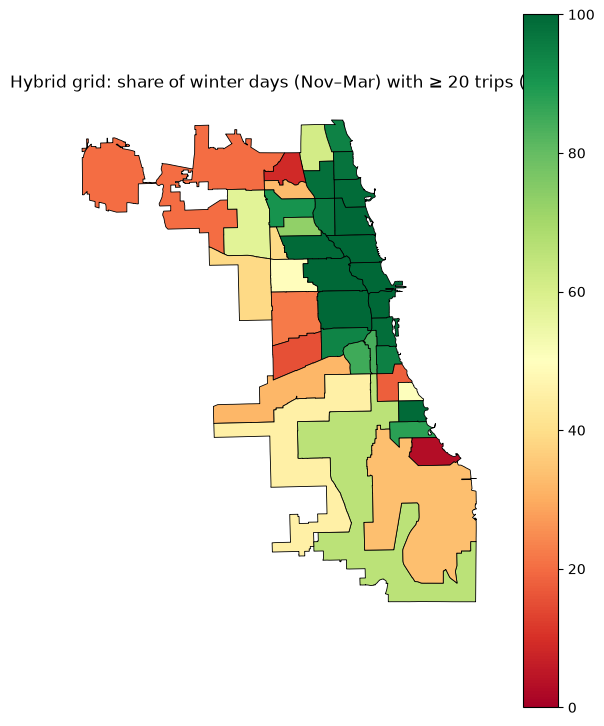

In [40]:
winter = ~warm
pct_winter = 100 * (cell_daily[winter] >= 20).mean()
pct_warm = 100 * (cell_daily[warm] >= 20).mean()

summary = pd.DataFrame({"% Apr–Oct days ≥ 20": pct_warm.round(0),
                        "% Nov–Mar days ≥ 20": pct_winter.round(0)})
print("Cells testable on ≥ 90% of winter days:", (pct_winter >= 90).sum(), "of", len(pct_winter))
print("Cells testable on < 50% of winter days:", (pct_winter < 50).sum())
print(f"Share of all winter cell-days testable: {100 * (cell_daily[winter] >= 20).values.mean():.0f}%")

cells_map["pct_winter"] = cells_map["cell_id"].map(pct_winter)
ax = cells_map.plot(figsize=(7, 9), column="pct_winter", cmap="RdYlGn", vmin=0, vmax=100,
                    legend=True, edgecolor="black", linewidth=0.6)
ax.set_title("Hybrid grid: share of winter days (Nov–Mar) with ≥ 20 trips (%)")
ax.set_axis_off()
plt.show()

#### Check 2: could the merged groups be split in summer?

➕ No: even in July, only 3 of the 49 merged zones have enough trips alone. A finer summer grid would gain almost nothing, so the grid stays the same all year.

In [41]:
july = daily.index.month == 7
merged_zones = zone_to_cell.groupby("cell_id").filter(lambda g: len(g) > 1)
check = merged_zones.assign(
    pct_july_20plus=merged_zones["zone_id"].map(lambda z: 100 * (daily.loc[july, z] >= 20).mean()),
    zone_name=merged_zones["zone_id"].map(zone_name))

print(check.sort_values(["cell_id", "pct_july_20plus"], ascending=[True, False])
           [["cell_id", "zone_name", "pct_july_20plus"]].round(0).to_string(index=False))
print("\nZones in merged groups with ≥ 20 trips on ≥ 90% of July days:",
      (check["pct_july_20plus"] >= 90).sum(), "of", len(check))

 cell_id              zone_name  pct_july_20plus
       9                Dunning             27.0
       9         Jefferson Park              7.0
       9            Forest Glen              1.0
       9              Montclare              0.0
       9                  Ohare              0.0
       9            Edison Park              0.0
       9           Norwood Park              0.0
      12           Portage Park             96.0
      12         Belmont Cragin             94.0
      14                 Austin             86.0
      14                Hermosa             69.0
      19     East Garfield Park             55.0
      19         North Lawndale             37.0
      19     West Garfield Park              0.0
      27        Grand Boulevard             99.0
      27                Oakland             16.0
      28        Washington Park             35.0
      28              Englewood             15.0
      28           Chicago Lawn              2.0
      28            

### 2.7 Final table: trips per cell per day → `data/daily_counts_cells.parquet`

- 179,228 rows = 37 cells × 4,844 days (zeros included)
- 56,972,942 trips (all clean trips minus those outside Chicago). 
- Columns: date, cell, trips, casual riders, e-bikes. 


- `data/external/cells.geojson` : the outline of each of the 37 cells → useful for drawing maps
- `daily_counts_cells.parquet`: trips per cell per day → for the model 

In [42]:
z2c = pd.read_csv("data/zone_to_cell.csv")
cell_names = z2c[["cell_id", "cell_name"]].drop_duplicates()

# 1. daily trips per cell (zone 0 = outside Chicago, left out)
zh = pd.read_parquet("data/zone_hourly_counts.parquet")
zh = zh[zh["zone_id"] > 0].copy()
zh["date"] = zh["hour"].dt.normalize()
daily_cells = (zh.merge(z2c[["zone_id", "cell_id"]], on="zone_id")
                 .groupby(["date", "cell_id"])[["n_trips", "n_casual", "n_electric"]].sum())

# 2. add the cell-days with 0 trips
all_dates = pd.date_range(daily_cells.index.get_level_values("date").min(),
                          daily_cells.index.get_level_values("date").max(), freq="D")
grid = pd.MultiIndex.from_product([all_dates, cell_names["cell_id"]], names=["date", "cell_id"])
daily_cells = (daily_cells.reindex(grid, fill_value=0)
                          .reset_index()
                          .merge(cell_names, on="cell_id"))
daily_cells.to_parquet("data/daily_counts_cells.parquet")

# 3. cell outlines for maps
cells_map = zones.merge(z2c, on="zone_id").dissolve(by="cell_id").reset_index()
cells_map[["cell_id", "cell_name", "geometry"]].to_file("data/external/cells.geojson", driver="GeoJSON")

print(len(daily_cells), "rows:", daily_cells["cell_id"].nunique(), "cells ×", len(all_dates), "days")
print("Trips:", daily_cells["n_trips"].sum(), "| expected:", zh["n_trips"].sum())
daily_cells.head()

179228 rows: 37 cells × 4844 days
Trips: 56972942 | expected: 56972942


,date,cell_id,n_trips,n_casual,n_electric,cell_name
0,2013-06-27,1,0,0,0,Rogers Park
1,2013-06-27,2,0,0,0,West Ridge
2,2013-06-27,3,0,0,0,Uptown
3,2013-06-27,4,0,0,0,Lincoln Square
4,2013-06-27,5,0,0,0,North Center



## 3. Stations (for later: locating anomalies)

➕ Not needed for the grid. Checks whether an anomaly found in a cell could later be located station by station (P3), and why quiet areas are quiet.

#### Q1. Can most trips be located at a station?

➕ Yes: 80–85% of trips start at a station (2022–2025). The rest are e-bikes left outside a station, located only roughly (~1 km). This share slowly decreases as e-bikes grow.

In [43]:
rows = []
for f in sorted(glob.glob("data/clean/*__*.parquet")):
    d = pd.read_parquet(f, columns=["started_at", "start_station_name"])
    d = d[d["started_at"].dt.year.between(2022, 2025)]
    if len(d):
        rows.append(d.groupby(d["started_at"].dt.year)["start_station_name"]
                     .agg(trips="size", at_station="count"))
st = pd.concat(rows).groupby(level=0).sum()
st["% at a station"] = (100 * st["at_station"] / st["trips"]).round(1)
print(st)

              trips  at_station  % at a station
started_at                                     
2022        5539204     4737137            85.5
2023        5563754     4732372            85.1
2024        5721284     4716248            82.4
2025        5399753     4304497            79.7


#### Q2. Why are some areas quiet: few stations, or little-used stations?

- Busy stations are on the north lakefront, downtown and around Hyde Park.
- The South and West Sides have stations everywhere, but far fewer per km² than downtown, and each is little used: quiet areas have both fewer stations and less use.
- Consequence: stations cover the whole city, so anomalies can later be located station by station in every cell, less precisely where stations are far apart.

2436 stations used in 2022–2025
                             n_stations  median_trips_per_station_per_day
cell_id cell_name                                                        
29.0    Kenwood                       9                               3.4
37.0    Edgewater                    10                              18.9
26.0    Douglas                      12                              11.6
25.0    Armour Square                12                               5.9
35.0    Bridgeport                   13                               3.7
24.0    Near South Side              15                              23.4
22.0    Lower West Side              17                               7.0
15.0    Avondale                     18                               2.2
1.0     Rogers Park                  18                               5.8
5.0     North Center                 18                               8.8
3.0     Uptown                       20                              20.3
4.0   

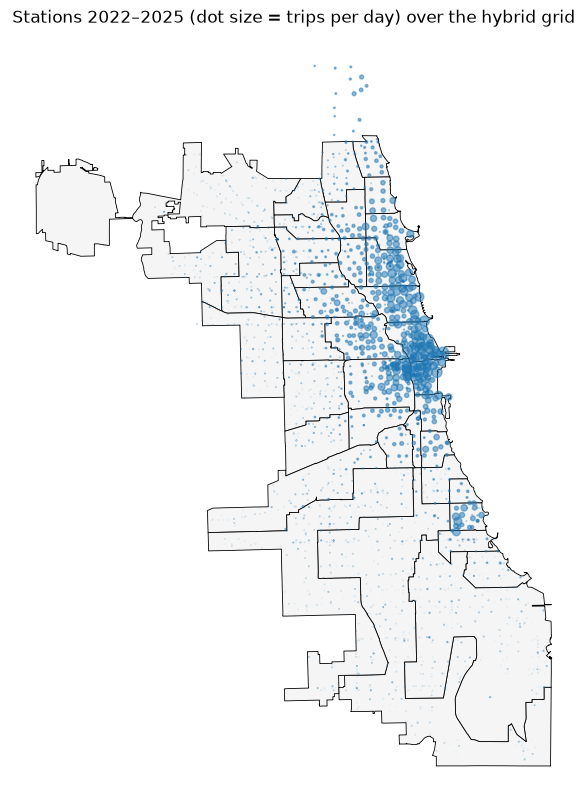

In [44]:
# 1. trips per station, 2022–2025 (position = median of the start positions)
parts = []
for f in sorted(glob.glob("data/clean/*__*.parquet")):
    d = pd.read_parquet(f, columns=["started_at", "start_station_name", "start_lat", "start_lng"])
    d = d[d["started_at"].dt.year.between(2022, 2025) & d["start_station_name"].notna()]
    if len(d):
        parts.append(d[["start_station_name", "start_lat", "start_lng"]])
st = pd.concat(parts)
stations = st.groupby("start_station_name").agg(n_trips=("start_lat", "size"),
                                                lat=("start_lat", "median"),
                                                lng=("start_lng", "median")).reset_index()
stations = gpd.GeoDataFrame(stations, crs="EPSG:4326",
                            geometry=gpd.points_from_xy(stations["lng"], stations["lat"]))
stations = gpd.sjoin(stations, cells_map[["cell_id", "cell_name", "geometry"]],
                     how="left", predicate="within").drop(columns="index_right")
stations["trips_per_day"] = stations["n_trips"] / 1461

# 2. per cell: number of stations and trips per station
per_cell = stations.groupby(["cell_id", "cell_name"]).agg(
    n_stations=("n_trips", "size"),
    median_trips_per_station_per_day=("trips_per_day", "median")).round(1)
print(len(stations), "stations used in 2022–2025")
print(per_cell.sort_values("n_stations").to_string())

# 3. map: dot size = trips
ax = cells_map.plot(figsize=(8, 10), facecolor="whitesmoke", edgecolor="black", linewidth=0.6)
stations.plot(ax=ax, markersize=stations["trips_per_day"] / 2, color="tab:blue", alpha=0.5)
ax.set_title("Stations 2022–2025 (dot size = trips per day) over the hybrid grid")
ax.set_axis_off()
plt.show()

#### Q3. What are the many stations with almost no trips?

➕ 785 of them are "public racks" (simple e-bike parking points, mostly in quiet areas), with only 0.4% of trips: negligible. Even without them, stations in the South and West stay little used.

In [45]:
stations["is_rack"] = stations["start_station_name"].str.contains("Public Rack", case=False, na=False)
print("Public racks:", stations["is_rack"].sum(), "| other stations:", (~stations["is_rack"]).sum())
print(f"Share of trips from public racks: {100 * stations.loc[stations['is_rack'], 'n_trips'].sum() / stations['n_trips'].sum():.1f}%")
print("\nNames of the 10 busiest racks:")
print(stations[stations["is_rack"]].nlargest(10, "n_trips")[["start_station_name", "trips_per_day"]].round(1).to_string(index=False))

docks = stations[~stations["is_rack"]]
per_cell = pd.DataFrame({
    "docking stations": docks.groupby("cell_name").size(),
    "public racks": stations[stations["is_rack"]].groupby("cell_name").size(),
    "median trips/day per docking station": docks.groupby("cell_name")["trips_per_day"].median().round(1),
}).fillna(0).astype({"docking stations": int, "public racks": int})
print("\n", per_cell.sort_values("median trips/day per docking station").to_string())

Public racks: 785 | other stations: 1651
Share of trips from public racks: 0.4%

Names of the 10 busiest racks:
                         start_station_name  trips_per_day
  Public Rack - Washtenaw Ave & Superior St            1.3
 Public Rack - Milwaukee Ave & Diversey Ave            1.0
 Public Rack - Christiana Ave & Belmont Ave            1.0
     Public Rack - Woodlawn Ave & 63rd St N            0.9
     Public Rack - Hyde Park Blvd & 53rd St            0.8
   Public Rack - Hamlin Ave & Fullerton Ave            0.8
    Public Rack - Hamlin Ave & Montrose Ave            0.8
   Public Rack - Kostner Ave & Armitage Ave            0.7
Public Rack - Spaulding Ave & Evergreen Ave            0.7
       Public Rack - Kedzie Ave & Argyle St            0.7

                      docking stations  public racks  median trips/day per docking station
cell_name                                                                                
Group 28 (12 areas)               193           160      

**Real docking stations vs public racks.** Goal: check whether the many low-traffic "stations" are simple public racks (e-bike parking points) rather than docking stations, and recount per cell: number of docking stations, number of racks, and the share of trips from each. Result: [to fill after running].

➕ Result: 785 of 2,436 are public racks (simple e-bike parking points), mostly in quiet cells, carrying only 0.4% of trips: negligible. Without them, docking stations in the South and West groups still have a median of about 0–0.3 trips per day, against 10–30 in busy cells. (Not checked: some stations may be recent, which lowers their daily average.)